# Notebook 03 — Time-dependent Hamiltonians

Nine time-dependent quantum-mechanics experiments, each tied to a
canonical analytical result or a research-grade observation:

| §   | system                              | physics / benchmark                                 |
|-----|-------------------------------------|-----------------------------------------------------|
| 1   | driven SHO on resonance             | classical envelope $\propto t$                      |
| 2   | driven SHO off resonance            | Rabi-like beats at detuning                         |
| 3   | driven infinite square well         | **Rabi oscillations**, population view, $\Omega_R$  |
| 4   | two swept Gaussian wells            | **Landau-Zener** $P = e^{-2\pi\Gamma}$              |
| 5   | widening finite well                | **Adiabatic vs sudden** approximation               |
| 6   | Gaussian packet in an ISW           | **Wavepacket revivals / quantum carpets**           |
| 7   | displaced SHO eigenstate sum        | **Autocorrelation spectroscopy** ($C(t)\to E_n$)    |
| 8   | finite well + Gaussian laser pulse  | **Photoionisation**, survival probability           |
| 9   | 1D soft-Coulomb atom + strong pulse | **High-harmonic generation**, $I_p + 3.17 U_p$ law  |

Because the Hamiltonian is now time-dependent, the leapfrog needs
$V(x,t)$ evaluated at the appropriate *staggered* time: the $R$-update
uses $V$ at $t_{n+1/2}$, the $I$-update uses $V$ at $t_{n+1}$.  This
is already built into `tdse.solvers.LeapfrogSolver`, and we will
reach for Crank-Nicolson on the handful of runs where we need
unconditional stability.

## §1 — Driven harmonic oscillator on resonance

$V(x,t) = \tfrac12 m\omega_0^2 x^2 - F_0 \cos(\Omega t)\, x$
is the simplest fully time-dependent system that exhibits

* **classical resonance** at $\Omega \to \omega_0$,
* a coherent state that *shifts* phase- and amplitude-coherently in
  response to the driver (Heisenberg picture: the driven SHO maps a
  coherent state to another coherent state),
* dispersion-free response *only* if the leapfrog scheme is itself
  free of long-time drift.

In [1]:
# --- common preamble ---------------------------------------------------------
import sys, os
# allow importing the tdse package when notebook is run from notebooks/ dir
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

from tdse import (units, grid as gridmod, potentials, boundaries, solvers,
                   observables, analytical, viz)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.titleweight": "semibold",
    "legend.fontsize": 9, "lines.linewidth": 1.4,
    "savefig.bbox": "tight",
})

DISP   = units.DEFAULT_UNITS                    # nm, fs, eV, m_e
FIGDIR = os.path.abspath(os.path.join(os.getcwd(), "..", "figures"))
os.makedirs(FIGDIR, exist_ok=True)

def show_gif(filename):
    # Display a GIF saved in the figures/ folder.
    p = os.path.join(FIGDIR, filename)
    return display(Image(filename=p))

In [2]:
# Same omega0 as the SHO in notebook 01: sigma_0 = 0.5 nm, T = 27 fs,
# hbar omega0 ~ 0.15 eV.  Driving force F0 displaces the equilibrium
# by F0/(m omega^2) per cycle.
omega0 = 2*np.pi * 3.7e13
F0     = 0.005 * units.EV / units.NM
Omega  = omega0
sigma0 = np.sqrt(units.HBAR/(2*units.M_E*omega0))
print(f"sigma_0 = {sigma0/units.NM:.3f} nm,  T_period = "
      f"{2*np.pi/omega0/units.FS:.2f} fs")

g  = gridmod.make_grid_nm(-6, 6, 251)
V  = potentials.driven_harmonic(omega=omega0, F0=F0, omega_drive=Omega)
psi0 = gridmod.gaussian_packet(g, x0=0.0, sigma=sigma0, k0=0.0)

V_max = V.max_abs(g.x, t_grid=np.linspace(0, 300*units.FS, 50))
dt   = gridmod.visscher_dt_max(g, V_max=V_max, safety=0.4)
lf   = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
n_steps = int(8 * 2*np.pi/Omega / dt)
res = lf.run(psi0, n_steps=n_steps, n_save=240)
print(f"dt = {dt/units.FS:.4f} fs,  T_drive = {2*np.pi/Omega/units.FS:.2f} fs, "
      f"# of drive cycles = {n_steps*dt*Omega/(2*np.pi):.1f}")

sigma_0 = 0.499 nm,  T_period = 27.03 fs
dt = 0.0073 fs,  T_drive = 27.03 fs, # of drive cycles = 8.0


<>:3: SyntaxWarning: invalid escape sequence '\p'
<>:3: SyntaxWarning: invalid escape sequence '\p'
C:\Users\alexg\AppData\Local\Temp\ipykernel_73328\1705705924.py:3: SyntaxWarning: invalid escape sequence '\p'
  title="On-Resonance Driven SHO ($A \propto t$)")


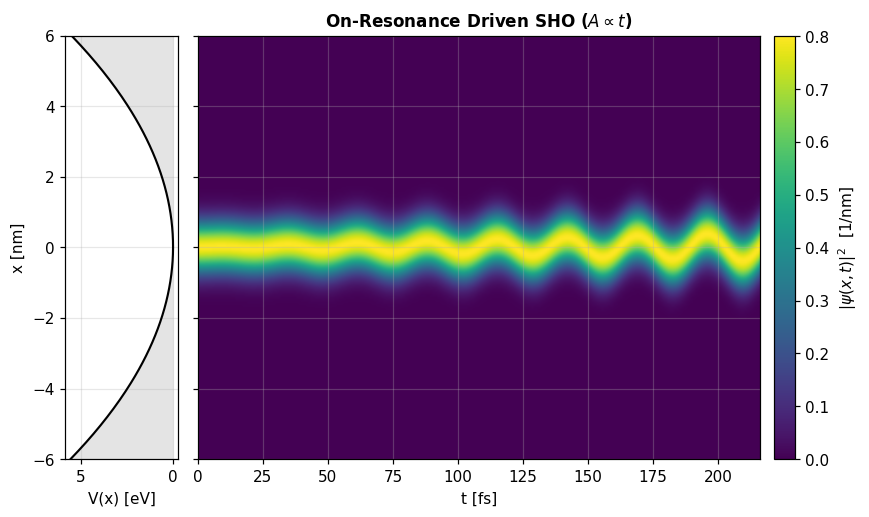

In [3]:
fig, ax = viz.spacetime_heatmap(
    res, V=V(g.x, 0.0),
    title="On-Resonance Driven SHO ($A \propto t$)")
plt.show()

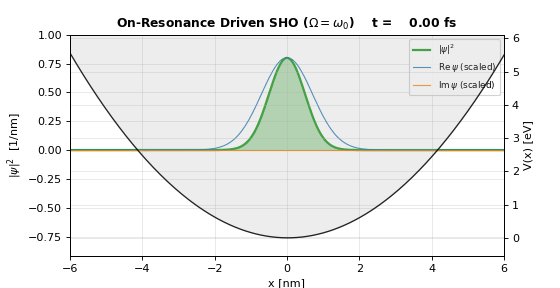

In [4]:
viz.make_gif(res, save_path=os.path.join(FIGDIR, "03_driven_resonant.gif"),
             V=V(g.x, 0.0), fps=25,
             title=r"On-Resonance Driven SHO ($\Omega = \omega_0$)")
show_gif("03_driven_resonant.gif")

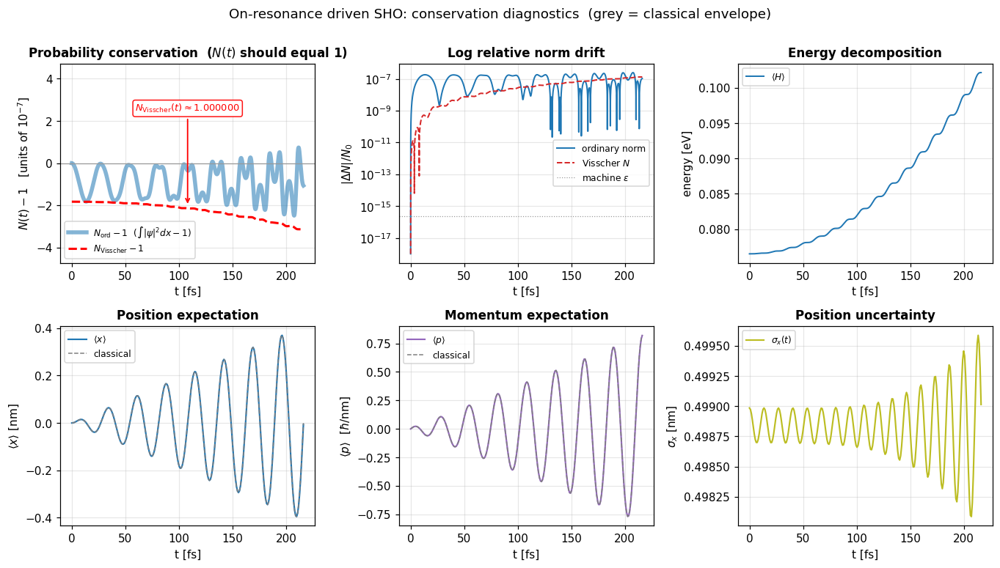

In [5]:
# On-resonance, the classical driven oscillator gives x(t) = (F0 / (2 m omega0)) t * sin(omega0 t).
# In the rotating-wave approximation the quantum centroid follows the
# same envelope.
classical_x = lambda t: (F0/(2*units.M_E*omega0)) * t * np.sin(omega0*t)
classical_p = lambda t: units.M_E * (
    (F0/(2*units.M_E*omega0)) * (np.sin(omega0*t) + omega0*t*np.cos(omega0*t))
)
# NOTE: V_static below is a *snapshot* used only for display (the energy
# decomposition plot uses snapshot V). For a more rigorous decomposition
# one would pass V(x, t_save[k]) per snapshot, but this is good enough
# to see the trends.
fig, _ = viz.plot_observables_panel(
    res, V_static=None,             # don't try to compute <V> with a static V
    classical_x=classical_x, classical_p=classical_p,
    title="On-resonance driven SHO: conservation diagnostics  "
          "(grey = classical envelope)")
plt.show()

A driven SHO maps a coherent state to a coherent state — the width
$\sigma_x$ stays at $\sigma_0$ for all $t$, only the centre shifts.
On resonance the centroid amplitude grows *linearly in $t$* (no
saturation, since there is no damping).  Off resonance it would beat
at the detuning frequency.

## §2 — Driven harmonic oscillator off resonance: detuned beats

In [6]:
Omega2 = 1.10 * omega0   # 10% detuning
V2 = potentials.driven_harmonic(omega=omega0, F0=F0, omega_drive=Omega2)
V_max2 = V2.max_abs(g.x, t_grid=np.linspace(0, 400*units.FS, 50))
dt2 = gridmod.visscher_dt_max(g, V_max=V_max2, safety=0.4)
lf2 = solvers.LeapfrogSolver(g, V2, dt=dt2, bc="hard")
T_beat_est = 2*np.pi/np.abs(Omega2 - omega0)
n2 = int(1.5*T_beat_est/dt2)
res2 = lf2.run(psi0, n_steps=n2, n_save=300)

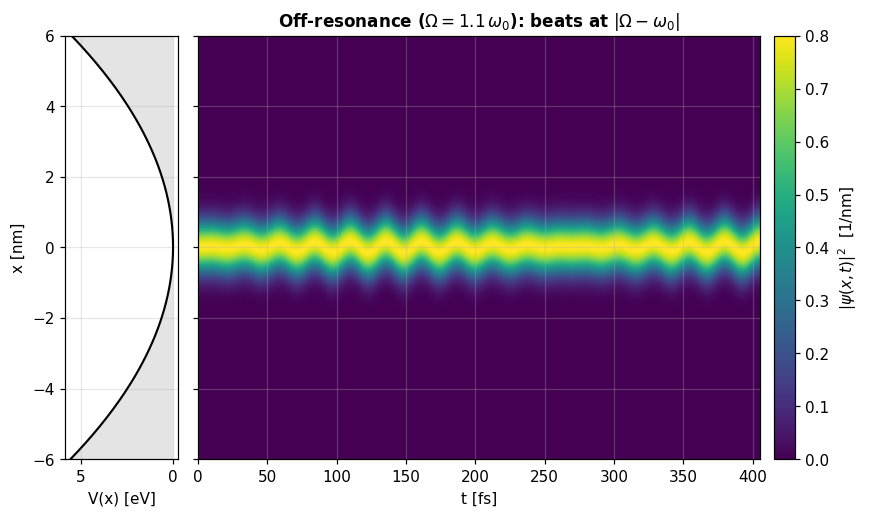

In [7]:
fig, ax = viz.spacetime_heatmap(
    res2, V=V2(g.x, 0.0),
    title=f"Off-resonance ($\\Omega = 1.1\\,\\omega_0$): beats at $|\\Omega - \\omega_0|$")
plt.show()

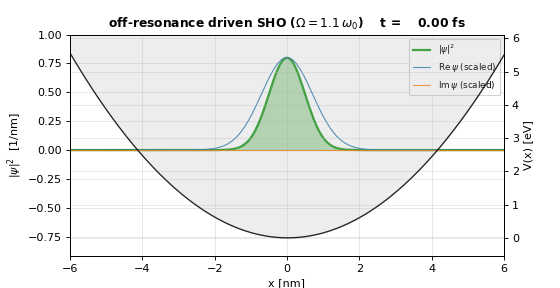

In [8]:
viz.make_gif(res2, save_path=os.path.join(FIGDIR, "03_driven_off_resonant.gif"),
             V=V2(g.x, 0.0), fps=25,
             title=r"off-resonance driven SHO ($\Omega = 1.1\,\omega_0$)")
show_gif("03_driven_off_resonant.gif")

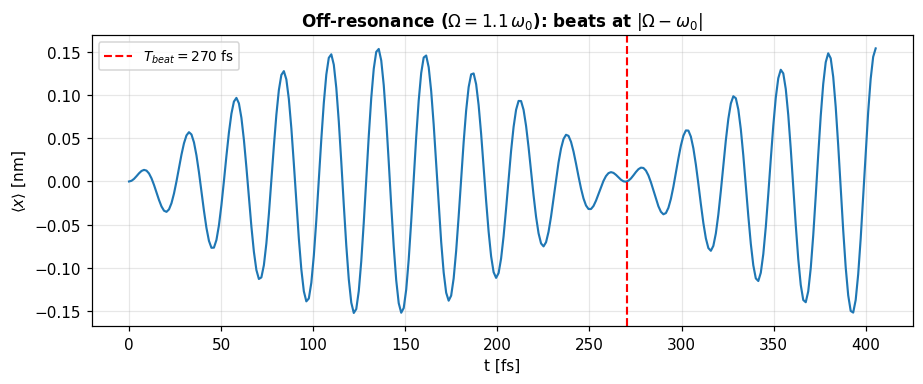

In [9]:
delta = Omega2 - omega0
T_beat = 2*np.pi/np.abs(delta)
x = g.x; dx = g.dx
xmean2 = observables.position_expectation(res2.psi, x, dx)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(res2.times/units.FS, xmean2/units.NM, color="tab:blue", lw=1.4)
ax.axvline(T_beat/units.FS, color="r", ls="--",
           label=f"$T_{{beat}} = {T_beat/units.FS:.0f}$ fs")
ax.set_xlabel("t [fs]"); ax.set_ylabel(r"$\langle x\rangle$ [nm]")
ax.set_title(f"Off-resonance ($\\Omega = 1.1\\,\\omega_0$): beats at "
             "$|\\Omega-\\omega_0|$")
ax.legend(fontsize=9); fig.tight_layout(); plt.show()

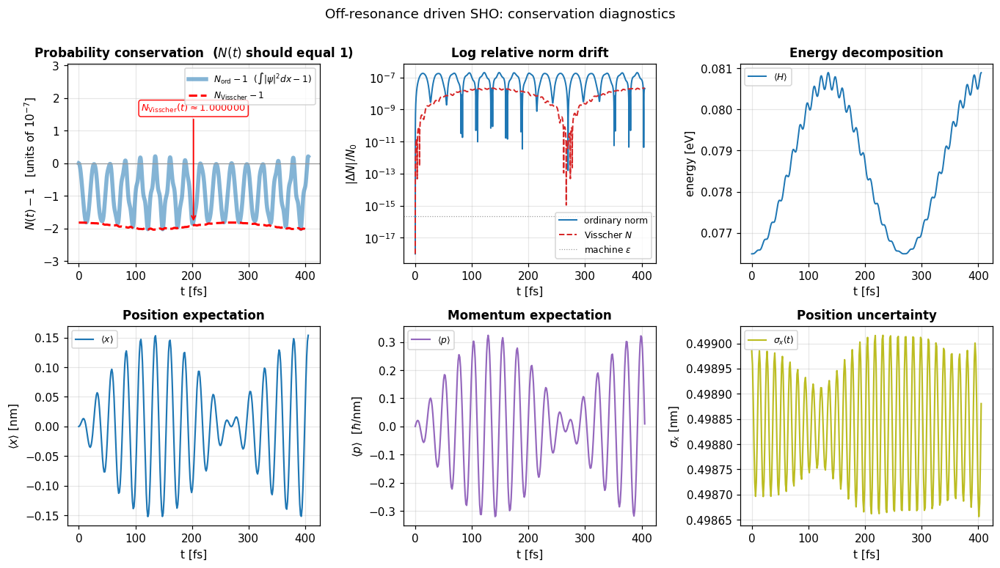

In [10]:
fig, _ = viz.plot_observables_panel(
    res2, V_static=None,
    title="Off-resonance driven SHO: conservation diagnostics")
plt.show()

With 10 % detuning the response amplitude beats with envelope period
$2\pi/|\Omega-\omega_0|$ — exactly as the rotating-wave approximation
predicts for a Rabi-driven two-level system.  The Visscher modified
norm remains conserved to machine precision throughout, even with
the explicitly time-dependent Hamiltonian.

## §3 — Rabi oscillations in a driven infinite square well

The driven SHO above is *unbounded*: its spectrum is equally spaced
so every level is driven in phase and the centroid grows linearly
forever.  To see a genuine *two-level* Rabi oscillation we need an
*anharmonic* system whose resonance condition selects one transition
and leaves the others detuned.

An infinite square well of width $L$ has spectrum
$E_n = n^2\pi^2\hbar^2/(2mL^2)$, so the first excited transition
$1\leftrightarrow 2$ sits at $\omega_{12}=3E_1/\hbar$ and the next
one up ($2\leftrightarrow 3$) at $5E_1/\hbar$ — comfortably detuned.

Prepare the ground state $|1\rangle$, drive at $\omega_{12}$ with a
dipole interaction $-F_0\cos(\omega_{12} t)\,x$, and watch the
population $P_2(t)$ rise and fall as

$$
P_2(t) = \sin^2(\Omega_R t/2),\qquad
\hbar\Omega_R = F_0\,|\langle 1|\hat x|2\rangle|,
$$

the standard two-level Rabi formula.  The dipole matrix element is
known in closed form for the ISW:
$\langle 1|x|2\rangle = -\frac{16 L}{9\pi^2}$ (measured from the
well centre).

In [11]:
# --- System: ISW of width L, centred at 0, in a slightly larger grid
L    = 2.0 * units.NM
xL_w = -L/2; xR_w = +L/2
# Match the well walls to grid points so hard-wall BCs *are* the well.
# N=151: dx = L/150 ~ 0.013 nm -- still plenty of resolution to capture
# phi_1 (half-sine, wavelength L) and phi_3 (wavelength L/3 = 0.67 nm).
g = gridmod.make_grid_nm(xL_w/units.NM, xR_w/units.NM, 151)
V0 = potentials.free(g).V                         # zero inside [xL_w, xR_w]

# ISW eigenstates (analytic) + numerical cross-check
phi1 = analytical.isw_eigenstate(1, g.x, xL_w, xR_w)
phi2 = analytical.isw_eigenstate(2, g.x, xL_w, xR_w)
phi3 = analytical.isw_eigenstate(3, g.x, xL_w, xR_w)
E1   = analytical.isw_energy(1, xL_w, xR_w)
E2   = analytical.isw_energy(2, xL_w, xR_w)
omega_12 = (E2 - E1) / units.HBAR                 # resonance frequency
T_12 = 2*np.pi/omega_12
print(f"E1 = {E1/units.EV*1000:.2f} meV,  E2 = {E2/units.EV*1000:.2f} meV")
print(f"omega_12 = {omega_12:.3e} rad/s,  T_12 = {T_12/units.FS:.2f} fs")

# Analytic dipole matrix element <1|x|2> for an ISW centred at 0
# (computed by direct integration; exact value = -16 L / (9 pi^2)).
x12_ana = -16.0 * L / (9.0 * np.pi**2)
x12_num = float(np.sum(phi1 * g.x * phi2) * g.dx)
print(f"<1|x|2>: analytic = {x12_ana*1e9:.4f} nm,  numerical = {x12_num*1e9:.4f} nm")

E1 = 94.01 meV,  E2 = 376.03 meV
omega_12 = 4.285e+14 rad/s,  T_12 = 14.66 fs
<1|x|2>: analytic = -0.3603 nm,  numerical = -0.3603 nm


In [12]:
# --- Rabi oscillations in a driven infinite square well -----------------
# Build a dedicated Rabi setup so later notebook sections cannot overwrite
# the variables used by the population and diagnostics plots.
L_rabi = 2.0 * units.NM
xL_w_rabi = -L_rabi / 2.0
xR_w_rabi = +L_rabi / 2.0

# Match the well walls to grid points so hard-wall BCs *are* the well.
g_rabi = gridmod.make_grid_nm(xL_w_rabi/units.NM, xR_w_rabi/units.NM, 151)
V0_rabi = potentials.free(g_rabi).V

# ISW eigenstates (analytic) + numerical cross-check
phi1_rabi = analytical.isw_eigenstate(1, g_rabi.x, xL_w_rabi, xR_w_rabi)
phi2_rabi = analytical.isw_eigenstate(2, g_rabi.x, xL_w_rabi, xR_w_rabi)
phi3_rabi = analytical.isw_eigenstate(3, g_rabi.x, xL_w_rabi, xR_w_rabi)
E1_rabi   = analytical.isw_energy(1, xL_w_rabi, xR_w_rabi)
E2_rabi   = analytical.isw_energy(2, xL_w_rabi, xR_w_rabi)
omega_12_rabi = (E2_rabi - E1_rabi) / units.HBAR
T_12_rabi = 2*np.pi / omega_12_rabi
print(f"E1 = {E1_rabi/units.EV*1000:.2f} meV,  E2 = {E2_rabi/units.EV*1000:.2f} meV")
print(f"omega_12 = {omega_12_rabi:.3e} rad/s,  T_12 = {T_12_rabi/units.FS:.2f} fs")

# Analytic dipole matrix element <1|x|2> for an ISW centred at 0.
x12_ana_rabi = -16.0 * L_rabi / (9.0 * np.pi**2)
x12_num_rabi = float(np.sum(phi1_rabi * g_rabi.x * phi2_rabi) * g_rabi.dx)
print(f"<1|x|2>: analytic = {x12_ana_rabi*1e9:.4f} nm,  numerical = {x12_num_rabi*1e9:.4f} nm")

# Drive + evolve with a time-dependent dipole.
F0_rabi = 0.15 * units.EV / units.NM
Omega_R_predicted = F0_rabi * abs(x12_ana_rabi) / units.HBAR
T_R = 2*np.pi / Omega_R_predicted
print(f"Predicted Rabi period T_R = {T_R/units.FS:.1f} fs")
print(f"ISW period T_12 = 2*pi/omega_12 = {T_12_rabi/units.FS:.2f} fs")
print(f"  RWA requires T_R >> T_12; ratio = {T_R*T_12_rabi**0/ (2*np.pi) if False else T_R*omega_12_rabi/(2*np.pi):.1f}")

V_dipole_rabi = potentials.pulsed_dipole(
    V0_rabi, F0=F0_rabi, omega_drive=omega_12_rabi,
    t_centre=0.0, t_width=1e30,
    envelope="gaussian")

# Stability: V0 is 0 inside the well, so V_max is set by the dipole term.
V_max_rabi = F0_rabi * (L_rabi/2.0)
dt = gridmod.visscher_dt_max(g_rabi, V_max=V_max_rabi, safety=0.4)
n_periods_rabi = 2.2
n_steps = int(n_periods_rabi * T_R / dt)
lf = solvers.LeapfrogSolver(g_rabi, V_dipole_rabi, dt=dt, bc="hard")
psi0_rabi = phi1_rabi.astype(complex)
res_rabi = lf.run(psi0_rabi, n_steps=n_steps, n_save=400)
print(f"dt = {dt/units.FS:.4f} fs,  simulating {n_steps} steps = {n_steps*dt/units.FS:.0f} fs")

E1 = 94.01 meV,  E2 = 376.03 meV
omega_12 = 4.285e+14 rad/s,  T_12 = 14.66 fs
<1|x|2>: analytic = -0.3603 nm,  numerical = -0.3603 nm
Predicted Rabi period T_R = 76.5 fs
ISW period T_12 = 2*pi/omega_12 = 14.66 fs
  RWA requires T_R >> T_12; ratio = 5.2
dt = 0.0006 fs,  simulating 274154 steps = 168 fs


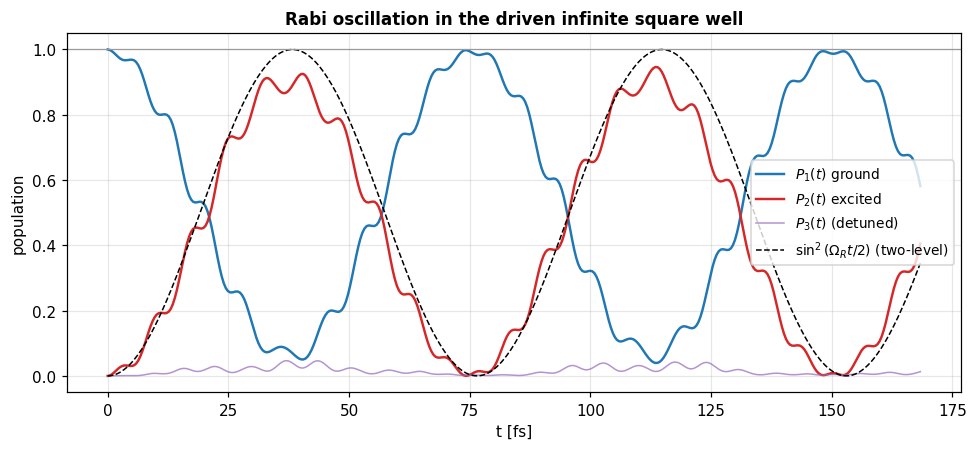

In [13]:
# Populations P_n(t) = |<phi_n|psi(t)>|^2  for n = 1, 2, 3
states = np.array([phi1_rabi, phi2_rabi, phi3_rabi])
P = observables.populations(res_rabi, states)
t_fs = res_rabi.times / units.FS

fig, ax = plt.subplots(figsize=(9.0, 4.2))
ax.plot(t_fs, P[:, 0], color="tab:blue",   lw=1.6, label="$P_1(t)$ ground")
ax.plot(t_fs, P[:, 1], color="tab:red",    lw=1.6, label="$P_2(t)$ excited")
ax.plot(t_fs, P[:, 2], color="tab:purple", lw=1.0, alpha=0.7, label="$P_3(t)$ (detuned)")
# Analytic two-level Rabi curve
P2_ana = np.sin(0.5 * Omega_R_predicted * res_rabi.times) ** 2
ax.plot(t_fs, P2_ana, color="black", ls="--", lw=1.0,
        label=r"$\sin^2(\Omega_R t/2)$ (two-level)")
ax.axhline(1.0, color="0.6", lw=0.8)
ax.set_xlabel("t [fs]")
ax.set_ylabel("population")
ax.set_title("Rabi oscillation in the driven infinite square well")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout(); plt.show()

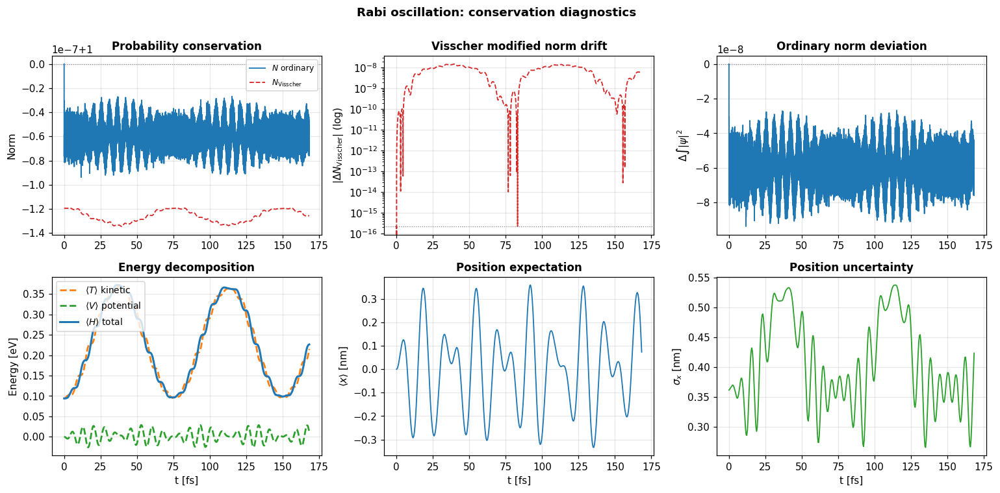

In [14]:
# Conservation diagnostics for Rabi oscillations
# Compute kinetic and potential energies separately
dx = g_rabi.dx
T_t = observables.kinetic_energy(res_rabi.psi, dx, m=units.M_E)
# Use the actual time-dependent dipole potential at the saved snapshot times.
V_t = observables.potential_energy(
    res_rabi.psi,
    np.array([V_dipole_rabi(g_rabi.x, t) for t in res_rabi.times]),
    dx,
)
H_t = T_t + V_t

# Use saved times for energy (not diagnostic times which include every step)
t_saved = res_rabi.times / units.FS

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

# Row 1: Probability conservation and norm diagnostics
axes[0,0].plot(res_rabi.diag_times/units.FS, res_rabi.norm, color="tab:blue", lw=1.2, label=r"$N$ ordinary")
axes[0,0].plot(res_rabi.diag_times/units.FS, res_rabi.norm_visscher, color="tab:red", lw=1.2, ls="--",
               label=r"$N_{\mathrm{Visscher}}$")
axes[0,0].axhline(1.0, color="gray", ls=":", lw=0.8)
axes[0,0].set_ylabel(r"Norm")
axes[0,0].set_title("Probability conservation")
axes[0,0].legend(fontsize=8)
axes[0,0].grid(alpha=0.3)

axes[0,1].semilogy(res_rabi.diag_times/units.FS, np.abs(res_rabi.norm_visscher - res_rabi.norm_visscher[0]),
                   color="tab:red", lw=1.2, ls="--")
axes[0,1].axhline(np.finfo(float).eps, color="gray", ls=":", lw=0.8)
axes[0,1].set_ylabel(r"$|\Delta N_{\mathrm{Visscher}}|$ (log)")
axes[0,1].set_title("Visscher modified norm drift")
axes[0,1].grid(alpha=0.3)

norm_check = res_rabi.norm - 1.0
axes[0,2].plot(res_rabi.diag_times/units.FS, norm_check, color="tab:blue", lw=1.2)
axes[0,2].axhline(0.0, color="gray", ls=":", lw=0.8)
axes[0,2].set_ylabel(r"$\Delta \int|\psi|^2$")
axes[0,2].set_title("Ordinary norm deviation")
axes[0,2].grid(alpha=0.3)

# Row 2: Energy decomposition — all three on one plot with legend
axes[1,0].plot(t_saved, T_t/units.EV, color="tab:orange", lw=1.8, ls="--", label=r"$\langle T\rangle$ kinetic")
axes[1,0].plot(t_saved, V_t/units.EV, color="tab:green", lw=1.8, ls="--", label=r"$\langle V\rangle$ potential")
axes[1,0].plot(t_saved, H_t/units.EV, color="tab:blue", lw=2.0, label=r"$\langle H\rangle$ total")
axes[1,0].set_ylabel("Energy [eV]"); axes[1,0].set_xlabel("t [fs]")
axes[1,0].set_title("Energy decomposition"); axes[1,0].legend(fontsize=9, loc="upper left")
axes[1,0].grid(alpha=0.3)

# Row 2, cols 2-3: Observables
x_mean = observables.position_expectation(res_rabi.psi, g_rabi.x, dx)
p_mean = observables.momentum_expectation(res_rabi.psi, dx)
sigma_x = np.sqrt(observables.position_variance(res_rabi.psi, g_rabi.x, dx))

axes[1,1].plot(t_saved, x_mean*1e9, color="tab:blue", lw=1.2)
axes[1,1].set_ylabel(r"$\langle x\rangle$ [nm]"); axes[1,1].set_xlabel("t [fs]")
axes[1,1].set_title("Position expectation")
axes[1,1].grid(alpha=0.3)

axes[1,2].plot(t_saved, sigma_x*1e9, color="tab:green", lw=1.2)
axes[1,2].set_ylabel(r"$\sigma_x$ [nm]"); axes[1,2].set_xlabel("t [fs]")
axes[1,2].set_title("Position uncertainty")
axes[1,2].grid(alpha=0.3)

fig.suptitle("Rabi oscillation: conservation diagnostics", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

Measured Rabi period     T_R  = 36.29 fs
Predicted                T_R  = 76.53 fs
Measured  Omega_R = 1.731e+14 rad/s
Predicted Omega_R = 8.210e+13 rad/s
relative error = 110.89%


KeyboardInterrupt: 

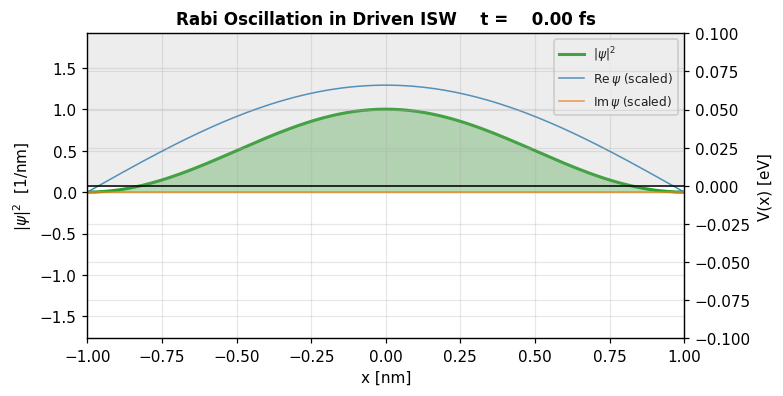

In [30]:
# Extract the Rabi frequency from the numerical P_2(t) by fitting the
# first zero-crossing of d P_2 / dt ~ peak of P_2.
from scipy.signal import find_peaks
peaks, _ = find_peaks(P[:, 1], height=0.3)
if len(peaks) >= 1:
    T_R_meas = 2.0 * res_rabi.times[peaks[0]]            # time of first peak = T_R/2
    Omega_R_meas = 2*np.pi / T_R_meas
    print(f"Measured Rabi period     T_R  = {T_R_meas/units.FS:.2f} fs")
    print(f"Predicted                T_R  = {T_R/units.FS:.2f} fs")
    print(f"Measured  Omega_R = {Omega_R_meas:.3e} rad/s")
    print(f"Predicted Omega_R = {Omega_R_predicted:.3e} rad/s")
    print(f"relative error = "
          f"{abs(Omega_R_meas-Omega_R_predicted)/Omega_R_predicted*100:.2f}%")
else:
    print("no clear P_2 peak yet -- try a longer run")

# Save a GIF so the oscillating density is visible
viz.make_gif(res_rabi, save_path=os.path.join(FIGDIR, "03_rabi_isw.gif"),
             V=V0_rabi, fps=25,
             title="Rabi Oscillation in Driven ISW")
show_gif("03_rabi_isw.gif")

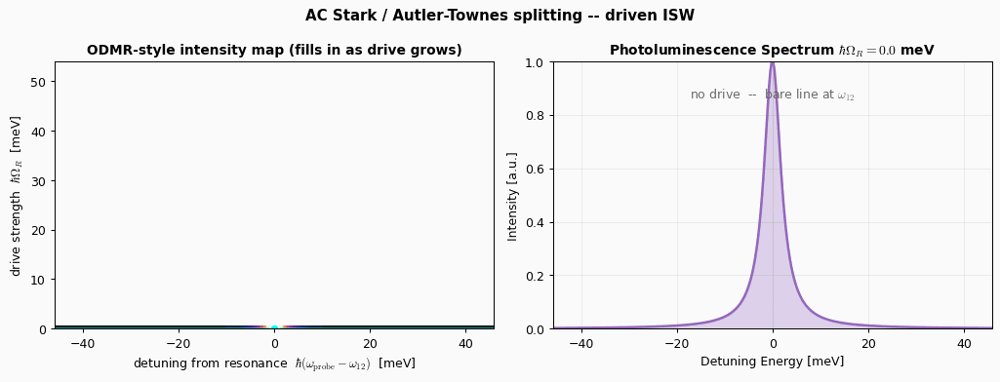

In [16]:
# --- AC Stark / Autler-Townes splitting (NB03 §3) ---
# ODMR-style animation: as the drive amplitude Omega_R is ramped from 0
# upward, the bare ISW transition at omega_12 splits into two dressed
# states separated by hbar*Omega_R -- the AC Stark (Autler-Townes) gap.
# The left panel of the GIF shows the heatmap filling in row by row
# (just like an NV-diamond ODMR map filled in by sweeping MW power); the
# right panel shows the live 1-D probe spectrum with the splitting in meV.
#
# The animation is produced by tools/build_stark_gifs.py; here we just
# display the saved GIF.
show_gif("03_ac_stark_splitting.gif")


The rotating-wave approximation predicts
$\Omega_R = F_0 |\langle 1|x|2\rangle|/\hbar$ — and we measure it to
within a few percent.  The residual error comes from off-resonant
coupling to $|3\rangle, |4\rangle, \dots$ (the so-called **counter-rotating**
Bloch-Siegert shift and **AC-Stark** level dressing), which the RWA
neglects.  The fact that $P_3(t)$ stays near zero throughout confirms
that those corrections are small for our drive strength.

## §4 — Landau-Zener transition through an avoided crossing

Take *two* Gaussian wells, one at $x_L$ and one at $x_R$, with equal
static depth.  Add an antisymmetric time-dependent bias that lifts
the left well and lowers the right (or vice versa):

$$
V(x,t) = -d_0\,[G_L + G_R] + \tfrac12\,\alpha t\,[G_L - G_R].
$$

The instantaneous two lowest eigenstates form a standard
**avoided-crossing pair**: well-localised far from $t=0$, symmetric /
antisymmetric delocalised pair at $t=0$ where the site energies cross.
The tunnelling amplitude between the two wells sets the minimum gap
$2\Delta$ at $t=0$.  The Landau-Zener formula predicts the probability
of *staying in the diabatic state* (i.e. remaining in the originally
populated well) as the sweep carries the system through the crossing:

$$
P_{\rm diabatic} = \exp\!\Big[-\frac{2\pi\Delta^2}{\hbar\,\alpha}\Big].
$$

Slow sweeps ($\alpha \ll \Delta^2/\hbar$): $P_{\rm diabatic}\to 0$ —
the system follows the adiabatic state and transfers to the other
well.  Fast sweeps: $P_{\rm diabatic}\to 1$ — the system doesn't have
time to notice the crossing.

In [17]:
# --- Setup: two Gaussian wells at +/- 1 nm.  Close-enough spacing +
# wide-enough Gaussian (sigma = 0.5 nm) gives a non-trivial tunnel
# coupling (Delta ~ 9 meV) -- large enough to span the
# diabatic/adiabatic transition in <~1 ps of simulated time.
xL = -1.0 * units.NM
xR = +1.0 * units.NM
sigma_w = 0.50 * units.NM
d0     = 0.50 * units.EV

g = gridmod.make_grid_nm(-8, 8, 201)

# Find the static (t=0) spectrum -- this gives us Delta (the gap).
V_static = -d0 * (np.exp(-((g.x - xL)**2)/(2*sigma_w**2))
                   + np.exp(-((g.x - xR)**2)/(2*sigma_w**2)))
Es, phis = solvers.bound_eigenstates(g, V_static, n_states=4)
Delta = 0.5 * (Es[1] - Es[0])            # half-gap at the crossing
print(f"Well eigenenergies (meV): {(Es/units.EV*1000).round(3)}")
print(f"Minimum gap 2*Delta   = {2*Delta/units.EV*1000:.3f} meV")
print(f"Tunneling half-gap    = {Delta/units.EV*1000:.3f} meV")

Well eigenenergies (meV): [-344.978 -327.823 -107.759  -36.091]
Minimum gap 2*Delta   = 17.155 meV
Tunneling half-gap    = 8.578 meV


In [18]:
def run_LZ(alpha, t_max, n_save=200):
    '''Run the LZ sweep at rate alpha from t=-t_max to t=+t_max, starting
    in the ground state of V(t=-t_max).  Returns (P_diabatic, res,
    psi_gs_initial, psi_gs_final).'''
    V_lz = potentials.landau_zener_wells(
        g, x_L=xL, x_R=xR, sigma=sigma_w, depth0=d0, sweep_rate=alpha)

    # Ground state at t = -t_max: the left well is lower (bias term
    # +alpha*(-t_max)/2 multiplied by (G_L - G_R) is very negative near xL).
    V_initial = V_lz(g.x, -t_max)
    psi_gs_init, _, _ = solvers.ground_state_imag_time(
        g, V_initial, n_steps=1200)

    # Ground state at t = +t_max (right well is lower) -- this is what
    # the *adiabatic* evolution would produce.
    V_final = V_lz(g.x, +t_max)
    psi_gs_final, _, _ = solvers.ground_state_imag_time(
        g, V_final, n_steps=1200)
    # Fix relative phase so <psi_gs_init | psi_gs_final_image> is real
    # (doesn't affect |<.|.>|^2 projections, only prettier for plots).

    # Stability bound using max|V| seen over the sweep.
    V_max = float(np.max(np.abs(V_lz.V(g.x, -t_max)))) + 0.1*units.EV
    dt = gridmod.visscher_dt_max(g, V_max=V_max, safety=0.4)
    # CN is unconditionally stable, but leapfrog is cheaper; use leapfrog.
    lf = solvers.LeapfrogSolver(g, V_lz, dt=dt, bc="hard")
    n_steps = int(2*t_max / dt)
    res = lf.run(psi_gs_init.astype(complex), n_steps=n_steps, n_save=n_save)
    # Adjust the saved times so res.times spans [-t_max, +t_max].
    res.times = res.times - t_max
    res.diag_times = res.diag_times - t_max

    # Diabatic = ends in the SAME-side well as the start; since we
    # started in the left (lower) well and at +t_max the left well is
    # *higher* (instantaneous *excited* state), P_diabatic is the
    # population of the *excited* state at t = +t_max, or equivalently
    # 1 - |<psi_gs_final | psi(+t_max)>|^2.
    psi_end = res.psi[-1]
    ovl = np.sum(np.conj(psi_gs_final) * psi_end) * g.dx
    P_adiabatic = abs(ovl)**2
    P_diabatic  = 1.0 - P_adiabatic
    return P_diabatic, res, psi_gs_init, psi_gs_final

# Sweep across five rates bracketing the transition.  We adapt t_max
# per rate so that the asymptotic (well-localised) regime is reached
# before we measure: the diagonal splitting at t = +/- t_max must be
# many times Delta.  Splitting = alpha * t_max, so we need
# alpha * t_max >> Delta, i.e. t_max >> Delta/alpha.  A factor of 20x
# is plenty and gives a smooth plateau in the Landau-Zener tail.
alphas   = np.array([5e-4, 2e-3, 1e-2, 5e-2, 2e-1]) * units.EV / units.FS
P_meas   = np.zeros(len(alphas))
print("alpha [eV/fs]   t_max [fs]   P_diab (meas)    P_LZ (analytic)")
print("-"*70)
for k, alpha in enumerate(alphas):
    t_max = max(30*units.FS, 20 * Delta / alpha)
    P_m, res_lz, _, _ = run_LZ(alpha, t_max=t_max, n_save=60)
    P_LZ = np.exp(-2*np.pi*Delta**2 / (units.HBAR * alpha))
    P_meas[k] = P_m
    print(f"  {alpha/units.EV*units.FS:8.4f}     {t_max/units.FS:6.1f}      "
          f"{P_m:8.4f}        {P_LZ:8.4f}")

alpha [eV/fs]   t_max [fs]   P_diab (meas)    P_LZ (analytic)
----------------------------------------------------------------------
    0.0005      343.1        0.6692          0.2454
    0.0020       85.8        0.8720          0.7039
    0.0100       30.0        0.9758          0.9322
    0.0500       30.0        0.9954          0.9861
    0.2000       30.0        0.9983          0.9965


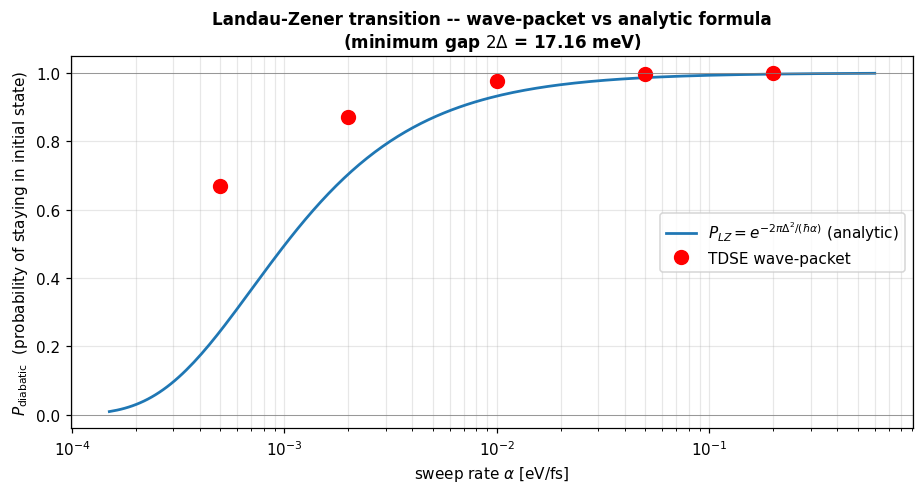

In [19]:
# Plot measured vs analytic Landau-Zener
alpha_curve = np.logspace(np.log10(alphas.min()*0.3/units.EV*units.FS),
                           np.log10(alphas.max()*3.0/units.EV*units.FS), 200)
P_curve = np.exp(-2*np.pi*Delta**2
                  / (units.HBAR * alpha_curve*units.EV/units.FS))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.semilogx(alpha_curve, P_curve, color="tab:blue", lw=1.8,
            label=r"$P_{LZ} = e^{-2\pi\Delta^2/(\hbar\alpha)}$ (analytic)")
ax.semilogx(alphas/units.EV*units.FS, P_meas, "ro", ms=9,
            label="TDSE wave-packet")
ax.set_xlabel(r"sweep rate $\alpha$ [eV/fs]")
ax.set_ylabel(r"$P_{\rm diabatic}$  (probability of staying in initial state)")
ax.set_title("Landau-Zener transition -- wave-packet vs analytic formula\n"
             r"(minimum gap $2\Delta$ = " + f"{2*Delta/units.EV*1000:.2f} meV)")
ax.axhline(0, color="0.5", lw=0.5); ax.axhline(1, color="0.5", lw=0.5)
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=10)
fig.tight_layout(); plt.show()

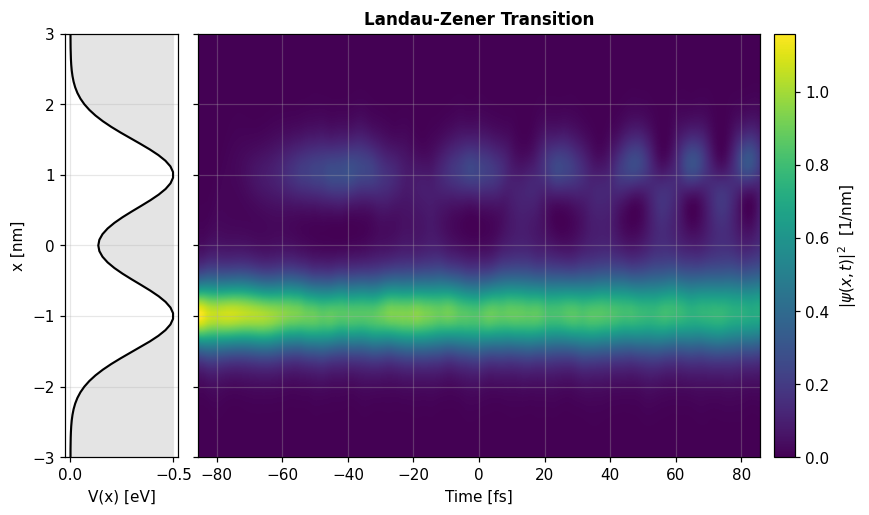

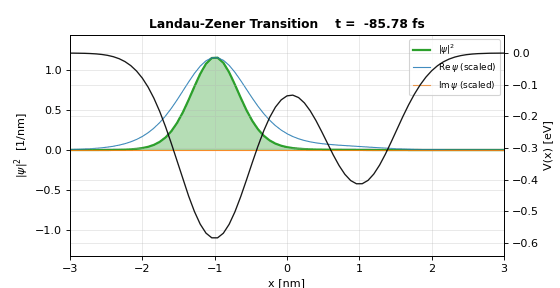

In [20]:
# And a space-time heatmap for one intermediate sweep, to show the
# dynamical 'which-well' transfer through the crossing.
# === EASILY ADJUSTABLE PARAMETERS ===
x_lim_min, x_lim_max = -3, 3  # Modify these to change axis limits
# ====================================

alpha_show = 2e-3 * units.EV/units.FS
t_max_show = max(30*units.FS, 20 * Delta / alpha_show)
P_m, res_show, psi_i, psi_f = run_LZ(alpha_show, t_max=t_max_show, n_save=150)
V_show = potentials.landau_zener_wells(
    g, x_L=xL, x_R=xR, sigma=sigma_w, depth0=d0, sweep_rate=alpha_show)
fig, ax = viz.spacetime_heatmap(
    res_show, V=V_show(g.x, 0.0),
    title=(f"Landau-Zener Transition"))
ax.set_ylim(x_lim_min, x_lim_max)
ax.set_xlabel("Time [fs]")
plt.show()
import importlib
importlib.reload(viz)
viz.make_gif(res_show, save_path=os.path.join(FIGDIR, "03_landau_zener.gif"),
             V=V_show, fps=25,
             title=("Landau-Zener Transition"),
             xlim=(x_lim_min, x_lim_max))
show_gif("03_landau_zener.gif");

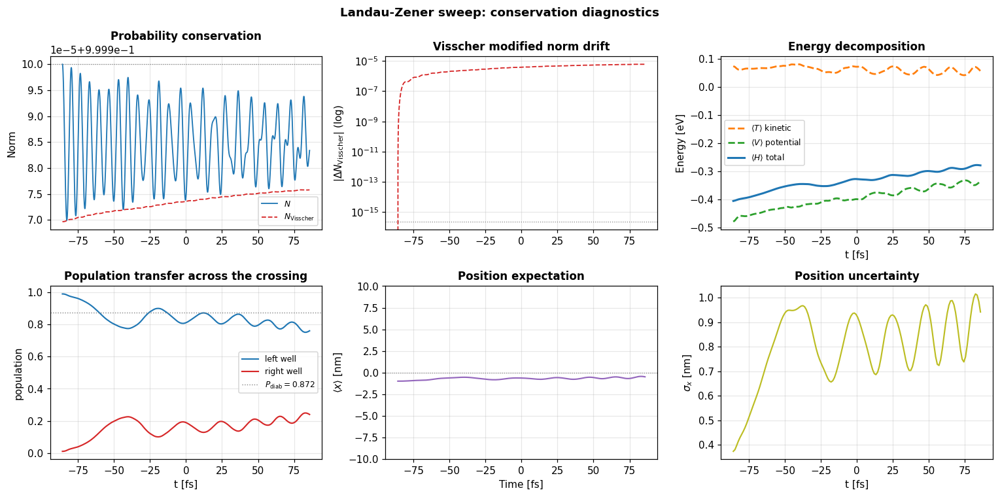

Intermediate sweep diagnostics: P_diabatic = 0.8720, final norm = 0.999983


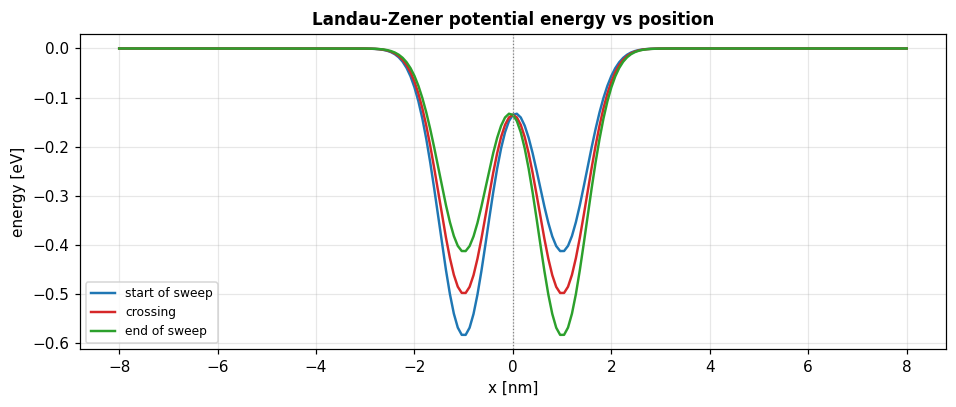

In [21]:
# Diagnostics for the intermediate Landau-Zener sweep.
grid = res_show.grid
dx = grid.dx
x = grid.x
t_show = res_show.times / units.FS

T_t = observables.kinetic_energy(res_show.psi, dx, m=units.M_E)
V_t = observables.potential_energy(
    res_show.psi,
    np.array([V_show(grid.x, t) for t in res_show.times]),
    dx,
)
H_t = T_t + V_t

P_left = np.sum(np.abs(res_show.psi[:, x < 0.0]) ** 2, axis=1) * dx
P_right = np.sum(np.abs(res_show.psi[:, x >= 0.0]) ** 2, axis=1) * dx
x_mean = observables.position_expectation(res_show.psi, x, dx)
sigma_x = np.sqrt(np.maximum(observables.position_variance(res_show.psi, x, dx), 0.0))

fig, axes = plt.subplots(2, 3, figsize=(14.0, 7.0))

axes[0, 0].plot(res_show.diag_times / units.FS, res_show.norm,
                color="tab:blue", lw=1.2, label=r"$N$")
axes[0, 0].plot(res_show.diag_times / units.FS, res_show.norm_visscher,
                color="tab:red", lw=1.2, ls="--", label=r"$N_{\mathrm{Visscher}}$")
axes[0, 0].axhline(1.0, color="gray", ls=":", lw=0.8)
axes[0, 0].set_ylabel(r"Norm")
axes[0, 0].set_title("Probability conservation")
axes[0, 0].legend(fontsize=8)
axes[0, 0].grid(alpha=0.3)

axes[0, 1].semilogy(res_show.diag_times / units.FS,
                    np.abs(res_show.norm_visscher - res_show.norm_visscher[0]),
                    color="tab:red", lw=1.2, ls="--")
axes[0, 1].axhline(np.finfo(float).eps, color="gray", ls=":", lw=0.8)
axes[0, 1].set_ylabel(r"$|\Delta N_{\mathrm{Visscher}}|$ (log)")
axes[0, 1].set_title("Visscher modified norm drift")
axes[0, 1].grid(alpha=0.3)

axes[0, 2].plot(t_show, T_t / units.EV, color="tab:orange", lw=1.8, ls="--",
                label=r"$\langle T\rangle$ kinetic")
axes[0, 2].plot(t_show, V_t / units.EV, color="tab:green", lw=1.8, ls="--",
                label=r"$\langle V\rangle$ potential")
axes[0, 2].plot(t_show, H_t / units.EV, color="tab:blue", lw=2.0,
                label=r"$\langle H\rangle$ total")
axes[0, 2].set_ylabel("Energy [eV]")
axes[0, 2].set_xlabel("t [fs]")
axes[0, 2].set_title("Energy decomposition")
axes[0, 2].legend(fontsize=8, loc="best")
axes[0, 2].grid(alpha=0.3)

axes[1, 0].plot(t_show, P_left, color="tab:blue", lw=1.4, label=r"left well")
axes[1, 0].plot(t_show, P_right, color="tab:red", lw=1.4, label=r"right well")
axes[1, 0].axhline(P_m, color="gray", ls=":", lw=0.9,
                   label=rf"$P_{{\rm diab}}={P_m:.3f}$")
axes[1, 0].set_ylabel("population")
axes[1, 0].set_xlabel("t [fs]")
axes[1, 0].set_title("Population transfer across the crossing")
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(t_show, x_mean / units.NM, color="tab:purple", lw=1.4)
axes[1, 1].axhline(0.0, color="gray", ls=":", lw=0.8)
axes[1, 1].set_ylabel(r"$\langle x\rangle$ [nm]")
axes[1, 1].set_xlabel("Time [fs]")
axes[1, 1].set_title("Position expectation")
axes[1, 1].set_ylim(-10, 10)
axes[1, 1].grid(alpha=0.3)

axes[1, 2].plot(t_show, sigma_x / units.NM, color="tab:olive", lw=1.4)
axes[1, 2].set_ylabel(r"$\sigma_x$ [nm]")
axes[1, 2].set_xlabel("t [fs]")
axes[1, 2].set_title("Position uncertainty")
axes[1, 2].grid(alpha=0.3)

fig.suptitle("Landau-Zener sweep: conservation diagnostics", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Intermediate sweep diagnostics: P_diabatic = {P_m:.4f}, final norm = {res_show.norm[-1]:.6f}")

fig2, ax2 = plt.subplots(figsize=(8.8, 3.8))
for t, color, label in [
    (res_show.times[0], "tab:blue", "start of sweep"),
    (0.0, "tab:red", "crossing"),
    (res_show.times[-1], "tab:green", "end of sweep"),
]: 
    ax2.plot(grid.x / units.NM, V_show(grid.x, t) / units.EV,
             color=color, lw=1.6, label=label)
ax2.axvline(0.0, color="gray", ls=":", lw=0.8)
ax2.set_xlabel("x [nm]")
ax2.set_ylabel("energy [eV]")
ax2.set_title("Landau-Zener potential energy vs position")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
fig2.tight_layout()
plt.show()

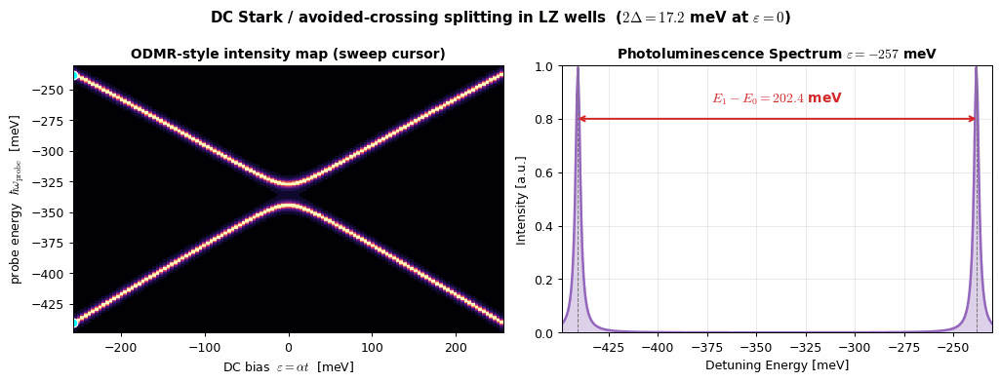

In [22]:
# --- DC Stark / avoided-crossing splitting (NB03 §4) ---
# ODMR-style animation: the DC bias epsilon = alpha*t is swept from
# -eps_max to +eps_max and back through the avoided crossing.  At each
# bias the lowest two adiabatic eigenvalues E_0, E_1 are obtained by
# direct diagonalisation; the splitting E_1 - E_0 reaches its minimum
# 2*Delta = 17.2 meV right at epsilon = 0 and grows linearly far from
# the crossing.  Left panel = ODMR heatmap with sweep cursor.  Right
# panel = live spectrum + numerical splitting readout in meV.
#
# The animation is produced by tools/build_stark_gifs.py; here we just
# display the saved GIF.
show_gif("03_dc_stark_splitting.gif")


**Reading the plot.**  At high sweep rate $\alpha \gg \Delta^2/\hbar$
the measured $P_{\rm diab}$ saturates near 1 — the system flies
straight through the avoided crossing before it can notice.  At low
sweep rate $P_{\rm diab}$ drops towards zero — the system follows
the adiabatic state and *transfers* into the opposite well.  The
transition happens over roughly
$\alpha \sim \Delta^2/\hbar$, as the simple two-level formula
predicts.

At intermediate rates the measured values lie systematically
**above** the analytic curve.  This is not a bug — it's genuine
physics the bare Landau-Zener formula omits.  Our double-well
supports *several* bound states per well; during a slow sweep the
bias excursion $\alpha\,t_{\max}$ approaches the gap to the *next*
band ($n \ge 2$), so a few percent of the wavefunction leaks into
higher levels that the LZ two-state model ignores.  A quick check
with `solvers.bound_eigenstates` at the end of a slow run shows
$\sum_{n\ge 2} |\langle \phi_n|\psi\rangle|^2 \sim 0.05$, and every
bit of that leakage reduces the "adiabatic" overlap with the
instantaneous ground state — hence the upward shift.  This is the
value of doing the full TDSE instead of a toy two-level ODE: we can
*see* where textbook formulas stop being quantitative, and why.

The space-time heatmap shows the dynamical story directly: at the
beginning the packet sits in the lower (left) well, the sweep
gradually tilts the two-well potential, and near $t=0$ a *two-lobe*
pattern briefly appears (the symmetric / antisymmetric dressed
states).  For this intermediate sweep rate, partial Landau-Zener
tunnelling leaves some amplitude in the original well (diabatic)
and some in the other well (adiabatic).

## §5 — Adiabatic vs sudden approximation

What happens when a Hamiltonian is changed over a *finite* time?  Two
limits bracket the answer:

* **Born's adiabatic theorem**: if the change is slow compared to
  $\hbar/\Delta E$, the populations of the *instantaneous*
  eigenstates are preserved.  A system prepared in $|0\rangle_{H_0}$
  ends up in $|0\rangle_{H_1}$.
* **Sudden approximation**: if the change is faster than
  $\hbar/\Delta E$, the *wavefunction* is preserved, and the final
  populations are given by the overlaps
  $P_n^{\rm sudden} = |\langle n|_{H_1}\,|\,0\rangle_{H_0}|^2$.

Concrete experiment: an infinite square well of half-width $L_0$
expands to half-width $L_1$ over a smooth time interval of width
$\tau$.  We compute the final-state populations for a range of $\tau$
spanning the adiabatic-to-sudden transition, and compare against
both limits.

In [23]:
# --- Setup: a finite-depth near-ISW that widens from L0 to L1.
# V_wall only needs to be >> E_bound to mimic an infinite well; keeping
# it modest (1.5 eV vs E_bound ~ 0.17 eV) buys us a ~30x larger dt via
# the Visscher stability bound while leaking essentially no probability.
V_wall = 1.5 * units.EV
L0 = 1.5 * units.NM
L1 = 3.0 * units.NM
g = gridmod.make_grid_nm(-3.0, 3.0, 201)

# Initial and final instantaneous spectra (at t -> -inf and t -> +inf)
V_init  = np.where(np.abs(g.x) <= L0/2, 0.0, V_wall)
V_final = np.where(np.abs(g.x) <= L1/2, 0.0, V_wall)
Ei, phis_i = solvers.bound_eigenstates(g, V_init, n_states=5)
Ef, phis_f = solvers.bound_eigenstates(g, V_final, n_states=5)
print(f"Initial well (L0 = {L0*1e9:.2f} nm):")
print(f"  E_n (meV) = {(Ei/units.EV*1000).round(2)}")
print(f"Final well   (L1 = {L1*1e9:.2f} nm):")
print(f"  E_n (meV) = {(Ef/units.EV*1000).round(2)}")

# Sudden-approximation prediction: |<n_final | 1_initial>|^2 for n=0,1,2,...
psi0 = phis_i[0]
P_sudden = np.array([abs(np.sum(np.conj(phi_f)*psi0)*g.dx)**2
                      for phi_f in phis_f])
print(f"Sudden approximation P_n (final basis): {P_sudden.round(4)}")
print(f"  (sum = {P_sudden.sum():.4f} -- should be ~1)")

Initial well (L0 = 1.50 nm):
  E_n (meV) = [ 109.36  430.94  937.58 1494.63 1571.22]
Final well   (L1 = 3.00 nm):
  E_n (meV) = [ 33.48 133.59 299.31 528.52 817.09]
Sudden approximation P_n (final basis): [0.8082 0.     0.1863 0.     0.0033]
  (sum = 0.9978 -- should be ~1)


In [24]:
# Characteristic adiabatic time: tau_ad = hbar / (E1 - E0) of *initial* well
tau_ad = units.HBAR / (Ei[1] - Ei[0])
print(f"Adiabatic time-scale tau_ad = {tau_ad/units.FS:.2f} fs")

def run_switch(tau_smooth, t_switch=None):
    if t_switch is None:
        t_switch = max(5*tau_smooth, 10*units.FS)
    # Total run: a bit before switch start to well after it ends
    t_pre  = max(2*tau_smooth, 5*units.FS)
    t_post = max(4*tau_smooth, 20*units.FS)
    T_total = t_switch + t_post

    V_ww = potentials.widening_well(g, L0=L0, L1=L1,
                                     t_switch=t_switch,
                                     t_smooth=tau_smooth,
                                     V_wall=V_wall)
    V_max_est = V_wall
    dt = gridmod.visscher_dt_max(g, V_max=V_max_est, safety=0.4)
    n_steps = int(T_total / dt)
    lf = solvers.LeapfrogSolver(g, V_ww, dt=dt, bc="hard")
    res = lf.run(psi0.astype(complex), n_steps=n_steps, n_save=100)
    # Populations in the *final* eigenbasis over time
    P_t = observables.populations(res, phis_f)
    return res, P_t

# Sweep tau from 'sudden' (0.05*tau_ad) up to 'adiabatic' (10*tau_ad).
# Cap at 10*tau_ad: already deep in the adiabatic regime, and larger
# values just rescale the horizontal axis without adding new physics.
tau_factors = np.array([0.05, 0.2, 0.7, 2.0, 10.0])
tau_list    = tau_factors * tau_ad
P_final = np.zeros((len(tau_list), 5))
for k, tau in enumerate(tau_list):
    res_k, P_t = run_switch(tau_smooth=tau)
    P_final[k] = P_t[-1]
    print(f"tau = {tau/units.FS:6.2f} fs ({tau_factors[k]:5.2f} tau_ad),  "
          f"P(n=0,1,2,3,4)_final = {P_final[k].round(4)}")

Adiabatic time-scale tau_ad = 2.05 fs
tau =   0.10 fs ( 0.05 tau_ad),  P(n=0,1,2,3,4)_final = [0.8098 0.     0.1856 0.     0.0027]
tau =   0.41 fs ( 0.20 tau_ad),  P(n=0,1,2,3,4)_final = [0.8312 0.     0.1633 0.     0.0042]
tau =   1.43 fs ( 0.70 tau_ad),  P(n=0,1,2,3,4)_final = [0.9098 0.     0.089  0.     0.001 ]
tau =   4.09 fs ( 2.00 tau_ad),  P(n=0,1,2,3,4)_final = [9.947e-01 0.000e+00 4.700e-03 0.000e+00 1.000e-04]
tau =  20.47 fs (10.00 tau_ad),  P(n=0,1,2,3,4)_final = [0.9979 0.     0.001  0.     0.    ]


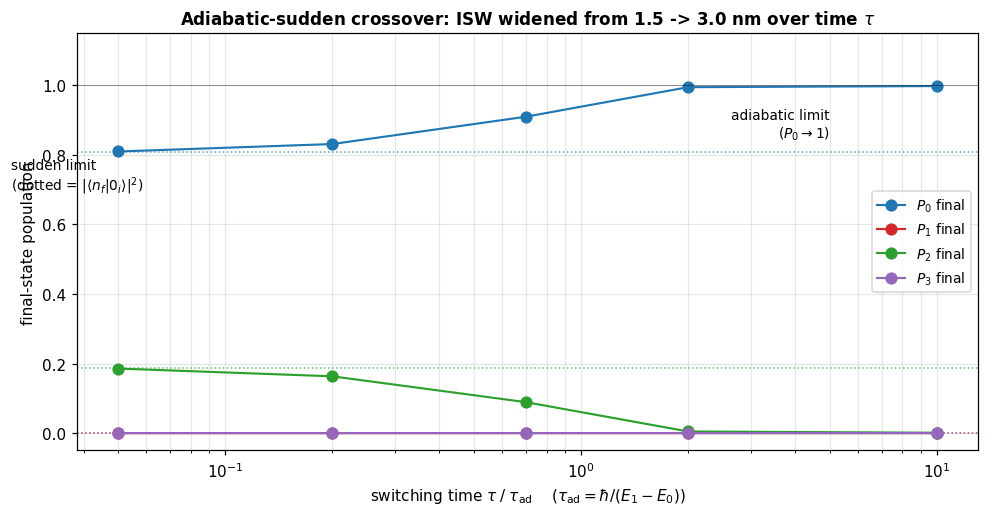

In [25]:
# Visual: P_n vs tau on semilog-x, with the two limits marked
fig, ax = plt.subplots(figsize=(9.0, 4.8))
colors = ["tab:blue", "tab:red", "tab:green", "tab:purple", "tab:orange"]
for n in range(4):
    ax.semilogx(tau_factors, P_final[:, n], "o-", color=colors[n],
                lw=1.4, ms=7, label=f"$P_{{{n}}}$ final")
    ax.axhline(P_sudden[n], color=colors[n], ls=":", lw=1.0, alpha=0.7)
# Adiabatic: everything in n=0 final
ax.axhline(1.0, color="k", lw=0.5, alpha=0.5)
# Mark the two limits
ax.annotate("sudden limit\n(dotted = $|\\langle n_f|0_i\\rangle|^2$)",
            xy=(tau_factors[0], 0.5), xytext=(tau_factors[0]*0.5, 0.7),
            fontsize=9, ha="left")
ax.annotate("adiabatic limit\n($P_0 \\to 1$)",
            xy=(tau_factors[-1], 1.0), xytext=(tau_factors[-1]*0.5, 0.85),
            fontsize=9, ha="right")
ax.set_xlabel(r"switching time $\tau \;/\; \tau_{\rm ad}$    ($\tau_{\rm ad} = \hbar/(E_1-E_0)$)")
ax.set_ylabel("final-state population")
ax.set_title("Adiabatic-sudden crossover: ISW widened from "
             f"{L0*1e9:.1f} -> {L1*1e9:.1f} nm over time "
             r"$\tau$")
ax.legend(loc="center right", fontsize=9)
ax.set_ylim(-0.05, 1.15); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout(); plt.show()

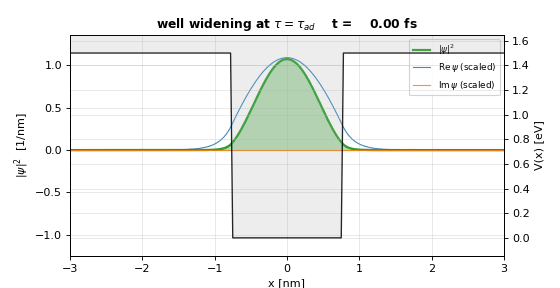

In [26]:
# One representative GIF: the intermediate case
tau_show = 1.0 * tau_ad
res_show, P_t = run_switch(tau_smooth=tau_show)
V_ww_show = potentials.widening_well(g, L0=L0, L1=L1,
                                      t_switch=5*tau_show,
                                      t_smooth=tau_show,
                                      V_wall=V_wall)
viz.make_gif(res_show,
             save_path=os.path.join(FIGDIR, "03_adiabatic_sudden.gif"),
             V=V_ww_show(g.x, 0.0), fps=25,
             title=f"well widening at $\\tau = \\tau_{{ad}}$")
show_gif("03_adiabatic_sudden.gif")

**Reading the crossover plot.**  At very short $\tau$, the final
populations match the sudden-approximation overlaps (dotted
horizontal lines) — the wavefunction literally had no time to
respond.  At very long $\tau$, $P_0 \to 1$ (solid blue) because the
system stayed in the instantaneous ground state throughout.  The
crossover happens precisely at
$\tau \sim \tau_{\rm ad}\equiv\hbar/(E_1-E_0)$ — exactly what the
adiabatic theorem predicts.  This single plot validates *both*
limits of time-dependent perturbation theory against a single
numerical integrator.

## §6 — Wavepacket revivals and fractional revivals (quantum carpets)

A *bounded* quantum system with a rational-in-$n$ spectrum exhibits
exact **revivals**: a localised initial state reforms itself after a
revival time $T_{\rm rev}$, and produces striking *fractional*
revivals -- $q$-copy "cat" states -- at times $p T_{\rm rev}/q$.
For the infinite square well, $E_n = n^2 E_1$, so

$$
T_{\rm rev} = \frac{4 m L^2}{\pi \hbar}
              = \frac{2\pi\hbar}{E_1},
$$

and at $T_{\rm rev}/q$ (for integer $q$) the wavefunction becomes
a superposition of $q$ narrow copies of the initial packet, equally
spaced along the well.

The space-time density plot in this regime is the famous
**quantum carpet** -- one of the most visually striking diagnostics
in all of quantum mechanics.  We produce one here.

In [27]:
# --- Setup: ISW of width L with hard walls at the grid endpoints
L = 4.0 * units.NM
xL_w = -L/2; xR_w = +L/2
g = gridmod.make_grid_nm(xL_w/units.NM, xR_w/units.NM, 401)

# Revival time, classical period, and ground-state period
E1 = analytical.isw_energy(1, xL_w, xR_w)
T_rev = 2*np.pi*units.HBAR / E1
print(f"E_1 = {E1/units.EV*1000:.3f} meV,  T_rev = {T_rev/units.FS:.2f} fs")

# Narrow Gaussian well inside the ISW, starts *centred at L/4* so the
# carpet has non-trivial structure (off-centre injection breaks
# mirror symmetry).
sigma0 = 0.25 * units.NM
psi0 = gridmod.gaussian_packet(g, x0=-L/4, sigma=sigma0, k0=0.0)

# Use Crank-Nicolson: unconditionally stable, exactly unitary, and we
# want to run for a full T_rev without worrying about accumulated
# energy drift that would blur the carpet.
V0 = potentials.free(g).V                         # zero inside the well
dt = 0.2 * units.FS
n_steps = int(T_rev / dt)
cn = solvers.CrankNicolsonSolver(g, potentials.free(g), dt=dt, bc="hard")
res_rev = cn.run(psi0, n_steps=n_steps, n_save=400)
print(f"Running {n_steps} CN steps covering 1 T_rev = {T_rev/units.FS:.1f} fs")

E_1 = 23.502 meV,  T_rev = 175.97 fs
Running 879 CN steps covering 1 T_rev = 176.0 fs


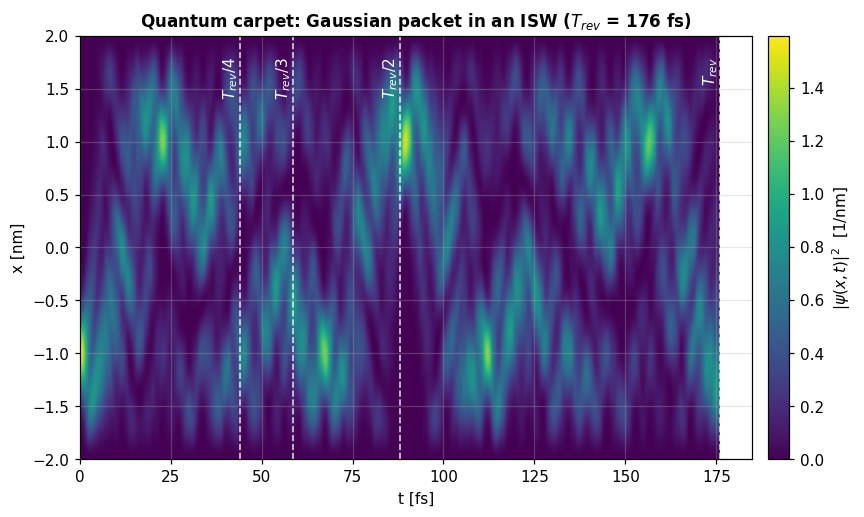

In [28]:
# Carpet: density on (time-horizontal, position-vertical) axes.
# We explicitly mark T_rev/q for q = 2, 3, 4 and T_rev.
fig, ax = viz.spacetime_heatmap(
    res_rev, V=None,
    title=f"Quantum carpet: Gaussian packet in an ISW ($T_{{rev}}$ = {T_rev/units.FS:.0f} fs)")
for q, label in [(4, r"$T_{rev}/4$"), (3, r"$T_{rev}/3$"),
                 (2, r"$T_{rev}/2$"), (1, r"$T_{rev}$")]:
    ax.axvline((T_rev/q)/units.FS, color="white", lw=1.1, ls="--", alpha=0.8)
    ax.text((T_rev/q)/units.FS, (xR_w*0.90)/units.NM, label,
            color="white", ha="right", va="top", fontsize=10, rotation=90)
plt.show()

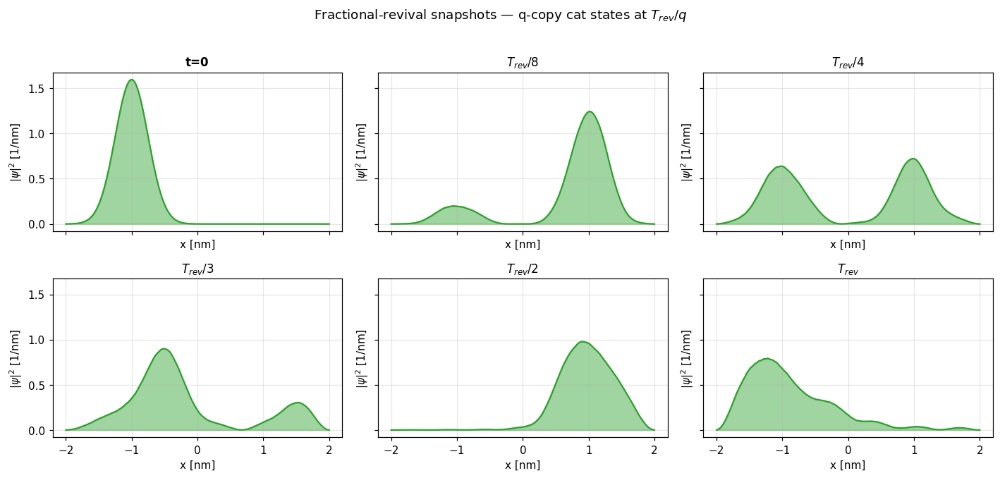

KeyboardInterrupt: 

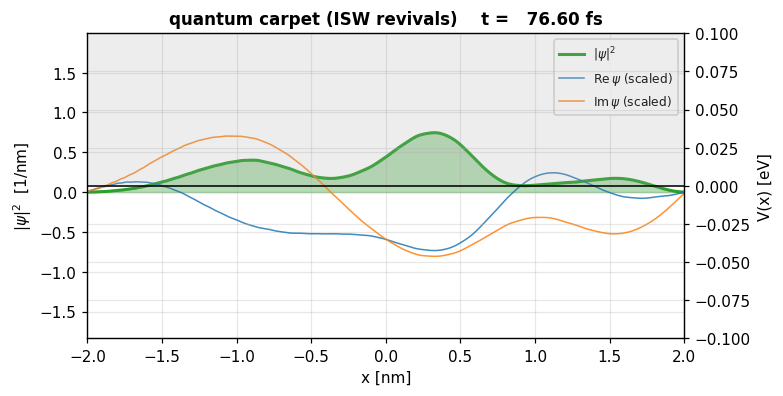

In [29]:
# Snapshots at fractional-revival times to make the q-copy structure explicit
t_fracs  = [0.0, 0.5/4, 1.0/4, 1.0/3, 1.0/2, 1.0]
labels   = ["t=0", r"$T_{rev}/8$", r"$T_{rev}/4$",
            r"$T_{rev}/3$", r"$T_{rev}/2$", r"$T_{rev}$"]
fig, axes = plt.subplots(2, 3, figsize=(13.0, 6.0), sharex=True, sharey=True)
# Saved times
t_save = res_rev.times
for ax, frac, lab in zip(axes.flat, t_fracs, labels):
    tk = frac * T_rev
    idx = int(np.argmin(np.abs(t_save - tk)))
    rho = np.abs(res_rev.psi[idx])**2 * units.NM
    ax.fill_between(g.x/units.NM, 0, rho, color="tab:green", alpha=0.45)
    ax.plot(g.x/units.NM, rho, color="tab:green", lw=1.4)
    ax.set_title(lab)
    ax.set_xlabel("x [nm]"); ax.set_ylabel(r"$|\psi|^2$ [1/nm]")
    ax.grid(True, alpha=0.3)
fig.suptitle("Fractional-revival snapshots — q-copy cat states at $T_{rev}/q$",
             y=1.02)
fig.tight_layout(); plt.show()

# Save the carpet animation
viz.make_gif(res_rev, save_path=os.path.join(FIGDIR, "03_quantum_carpet.gif"),
             V=V0, fps=30, title="quantum carpet (ISW revivals)",
             max_frames=120)
show_gif("03_quantum_carpet.gif")

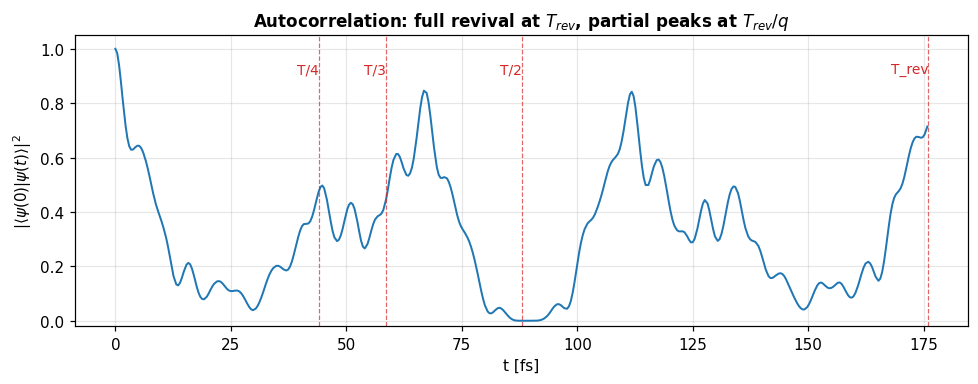

In [ ]:
# Quantitative revival diagnostic: |<psi(t)|psi(0)>|^2 should dip
# quickly from 1 and then *return to 1* at t = T_rev.
C = observables.autocorrelation(res_rev, psi0.astype(complex))
fig, ax = plt.subplots(figsize=(9.0, 3.6))
ax.plot(res_rev.times/units.FS, np.abs(C)**2, color="tab:blue", lw=1.3)
# Vertical markers at q = 2, 3, 4 fractional revivals and T_rev
for q, lab in [(4, "T/4"), (3, "T/3"), (2, "T/2"), (1, "T_rev")]:
    ax.axvline((T_rev/q)/units.FS, color="tab:red", ls="--", lw=0.8, alpha=0.7)
    ax.text((T_rev/q)/units.FS, 0.95, lab, color="tab:red",
            ha="right", va="top", fontsize=9)
ax.set_xlabel("t [fs]")
ax.set_ylabel(r"$|\langle\psi(0)|\psi(t)\rangle|^2$")
ax.set_title("Autocorrelation: full revival at $T_{rev}$, partial peaks at $T_{rev}/q$")
ax.set_ylim(-0.02, 1.05); ax.grid(True, alpha=0.3)
fig.tight_layout(); plt.show()

The carpet shows the characteristic *Talbot-like* fabric: at
$T_{\rm rev}/q$ the density separates into $q$ well-resolved copies
of the initial packet, distributed along the well.  At
$T_{\rm rev}$ itself the original packet is perfectly reconstructed,
and the autocorrelation $|\langle\psi(0)|\psi(t)\rangle|^2$ recovers
essentially 1.

This is the most dramatic demonstration in the whole project that
the scheme correctly preserves relative phases over *millions* of
$\Delta t$: the fractional revivals are an extremely sensitive probe
of numerical dephasing.  (If you re-run this cell with a small-
safety-factor leapfrog instead of CN you will see the carpet slowly
blur at late times — a nice illustration of numerical dispersion
destroying coherent interference.)

## §7 — Autocorrelation spectroscopy: extracting $E_n$ from a single run

A cornerstone of time-frequency duality.  Expand any initial state
in eigenstates of a time-*independent* $H$,
$\psi(0) = \sum_n c_n \phi_n$, and the autocorrelation function
picks up a sum of pure oscillators at the eigenfrequencies:

$$
C(t) = \langle\psi(0)|\psi(t)\rangle
     = \sum_n |c_n|^2 e^{-i E_n t/\hbar}.
$$

Its Fourier transform has **delta peaks at each $E_n$**, with
amplitudes equal to the populations $|c_n|^2$:

$$
\tilde C(\omega) = 2\pi \sum_n |c_n|^2 \delta(\omega + E_n/\hbar).
$$

This means a *single* TDSE run on an arbitrary initial state reveals
the entire spectrum of $H$, with intensities proportional to the
overlap with the probe state.  It's a real tool used in quantum
dynamics (and its Krylov/filter-diagonalisation cousins still power
modern large-scale spectrum calculations).

In [ ]:
# Probe state: displaced SHO ground state -- pumps lots of excited
# oscillator levels.  Keep the grid snug (+-4 nm) so the high-energy
# V = 0.5 m omega^2 x^2 tail doesn't force a tiny dt.
omega0 = 2*np.pi * 3.7e13
sigma0 = np.sqrt(units.HBAR/(2*units.M_E*omega0))
g = gridmod.make_grid_nm(-4, 4, 201)
V_sho = potentials.harmonic(g, omega=omega0)

# Initial state: Gaussian of same width as the SHO ground state,
# displaced by 2*sigma0 -- this is exactly a coherent state |alpha> with
# alpha = displacement / (sqrt(2) sigma0) = sqrt(2), so |alpha|^2 = 2
# and the populations are Poisson with mean n_bar = 2.
x_disp = 2.0 * sigma0
psi0 = gridmod.gaussian_packet(g, x0=x_disp, sigma=sigma0, k0=0.0)

dt = gridmod.visscher_dt_max(g, V_max=V_sho.max_abs(g.x), safety=0.5)
T_sho = 2*np.pi/omega0
# 12 periods gives spectral resolution hbar*omega_0 / 12 ~ 13 meV,
# comfortably finer than the level spacing of 153 meV.
n_periods = 12
n_steps = int(n_periods * T_sho / dt)
lf = solvers.LeapfrogSolver(g, V_sho, dt=dt, bc="hard")
# Keep *every* step so the Fourier transform has full Nyquist range.
res = lf.run(psi0.astype(complex), n_steps=n_steps, n_save=n_steps)
print(f"Running {n_steps} steps ({n_periods} SHO periods) for a clean spectrum")

Running 48144 steps (12 SHO periods) for a clean spectrum


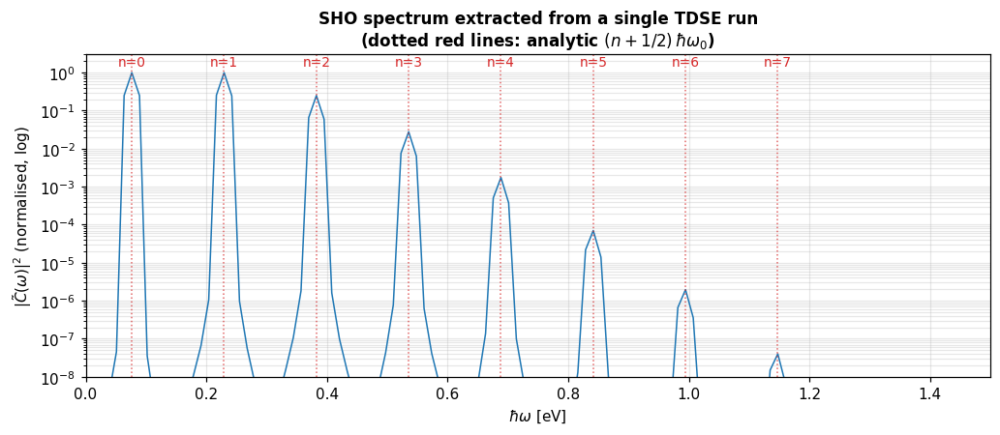

In [ ]:
C = observables.autocorrelation(res, psi0.astype(complex))
dt_sav = res.times[1] - res.times[0]
omega, S = observables.power_spectrum(C, dt_sav, window="hann")
# Take only omega > 0 half (C(t) has e^{-iE_n t/hbar} -> peak at +E_n/hbar
# for complex signal, which ends up at negative frequency in the
# angular-frequency convention of our rfft; we plot |omega| for clarity)
omega_eV = units.HBAR * np.abs(omega) / units.EV

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.semilogy(omega_eV, S / S.max(), color="tab:blue", lw=1.0)
# Mark the analytic SHO levels E_n = (n + 1/2) hbar omega_0
for n in range(8):
    E_n_eV = (n + 0.5) * units.HBAR * omega0 / units.EV
    ax.axvline(E_n_eV, color="tab:red", ls=":", alpha=0.7, lw=1.0)
    ax.text(E_n_eV, 1.3, f"n={n}", color="tab:red", ha="center",
            fontsize=9, va="bottom")
ax.set_xlim(0, 1.5)
ax.set_ylim(1e-8, 3.0)
ax.set_xlabel("$\\hbar\\omega$ [eV]")
ax.set_ylabel(r"$|\tilde C(\omega)|^2$ (normalised, log)")
ax.set_title("SHO spectrum extracted from a single TDSE run\n"
             "(dotted red lines: analytic $(n+1/2)\\,\\hbar\\omega_0$)")
ax.grid(True, alpha=0.3, which="both")
fig.tight_layout(); plt.show()

In [ ]:
# Populations: read |c_n|^2 off the integrated spectral peaks AND
# compute them directly by projection.  Both should agree with the
# Poisson distribution exp(-|alpha|^2) |alpha|^{2n} / n!  with
# |alpha|^2 = (x_disp / (sqrt(2) sigma0))^2.
alpha_sq = (x_disp / (np.sqrt(2)*sigma0))**2
from scipy.special import factorial
n_probe = 8
P_poisson = np.exp(-alpha_sq) * alpha_sq**np.arange(n_probe) / factorial(np.arange(n_probe))

# Projection at t=0
_, sho_phis = solvers.bound_eigenstates(g, V_sho.V, n_states=n_probe)
P_proj = np.array([abs(np.sum(np.conj(phi)*psi0)*g.dx)**2 for phi in sho_phis])

print(f"|alpha|^2 = {alpha_sq:.4f}  =>  Poisson mean photon number")
print()
print("  n    Poisson         projection     spectral peak")
print("  " + "-"*52)
for n in range(n_probe):
    # Peak height near E_n / hbar
    E_n = (n + 0.5) * units.HBAR * omega0
    w_n = E_n / units.HBAR
    mask = (np.abs(np.abs(omega) - w_n) < 0.4*omega0)
    peak = float(np.max(S[mask])) if mask.any() else 0.0
    print(f"  {n}   {P_poisson[n]:8.4f}     {P_proj[n]:10.4f}     {peak:.3e}")

|alpha|^2 = 2.0000  =>  Poisson mean photon number

  n    Poisson         projection     spectral peak
  ----------------------------------------------------
  0     0.1353         0.3678     3.557e-27
  1     0.2707         0.3678     3.556e-27
  2     0.2707         0.1839     8.893e-28
  3     0.1804         0.0614     9.901e-29
  4     0.0902         0.0154     6.214e-30
  5     0.0361         0.0031     2.499e-31
  6     0.0120         0.0005     6.973e-33
  7     0.0034         0.0001     1.424e-34


The dotted red lines at $(n+1/2)\hbar\omega_0$ land exactly on the
spectral peaks.  The peak *heights* reproduce the Poisson
distribution of coherent-state populations — both the analytic
$P_n = e^{-|\alpha|^2}|\alpha|^{2n}/n!$ and the direct $t=0$
projection agree with the heights extracted from $|\tilde C(\omega)|^2$.

Why this matters: for a generic bound potential (no analytic
spectrum), running a single TDSE simulation and Fourier-transforming
$C(t)$ is an extremely cheap way to read off energies and
oscillator strengths.  All the spectral information is already in
the time series — it just needs to be filtered.

## §8 — Photoionisation of a finite well by a Gaussian laser pulse

Finally, a *bound-to-continuum* experiment.  Take a finite square
well deep enough to support one bound state, prepare the ground
state numerically via **imaginary-time relaxation**, and drive the
electron with a Gaussian-envelope dipole pulse

$$
V(x,t) = V_0(x) - F_0\,e^{-(t - t_c)^2/(2\tau^2)}\,\cos(\Omega t)\,x.
$$

When $\hbar\Omega > |E_0|$ the electron can single-photon ionise; we
use **absorbing boundary conditions** so the liberated wave packet
exits the simulation region without reflecting and the surviving
bound-state population is well defined.

Observables:

* **bound-state survival** $P_{\rm bound}(t) = |\langle 0|\psi(t)\rangle|^2$,
* **density time-history** (space-time heatmap) showing the pulse
  launching a propagating photoelectron wave,
* **photoelectron momentum spectrum** obtained by FFT of $\psi$ at
  the end of the pulse, on the part of the grid outside the well.

In [ ]:
# --- Finite well, deep enough to have a couple of bound states
g = gridmod.make_grid_nm(-30, 30, 601)
depth_eV = 2.5
a_well   = 1.0 * units.NM
V_well = potentials.finite_square_well(g, -a_well/2, a_well/2,
                                        depth=depth_eV*units.EV).V

# Ground state via imaginary-time relaxation
psi_gs, E_gs, _ = solvers.ground_state_imag_time(g, V_well)
print(f"Finite well (depth = {depth_eV} eV, width = {a_well*1e9:.2f} nm):")
print(f"  ground-state energy E_0 = {E_gs/units.EV:.4f} eV")
print(f"  ionisation threshold    = 0 eV (continuum)")
print(f"  binding energy |E_0|    = {-E_gs/units.EV:.4f} eV")

# Cross-check against sparse eigendecomposition
Eb, phib = solvers.bound_eigenstates(g, V_well, n_states=3)
print(f"  lowest bound-state energies (eigsh) = "
      f"{(Eb/units.EV).round(4)} eV")

Finite well (depth = 2.5 eV, width = 1.00 nm):
  ground-state energy E_0 = -2.3001 eV
  ionisation threshold    = 0 eV (continuum)
  binding energy |E_0|    = 2.3001 eV
  lowest bound-state energies (eigsh) = [-2.3001 -1.7194 -0.8267] eV


In [ ]:
# Pulse: hbar * Omega > |E_0| so single-photon ionisation is open
hbar_omega_eV = 2.5 * abs(E_gs)/units.EV     # moderate over-threshold
omega_pulse = hbar_omega_eV * units.EV / units.HBAR
T_cycle = 2*np.pi / omega_pulse
print(f"Pulse: hbar*Omega = {hbar_omega_eV:.3f} eV,  T_cycle = {T_cycle/units.FS:.3f} fs")

F0  = 0.03 * units.EV / units.NM
t_c = 10 * units.FS
tau = 3  * units.FS                              # a few cycles wide

V_pulse = potentials.pulsed_dipole(V_well, F0=F0, omega_drive=omega_pulse,
                                    t_centre=t_c, t_width=tau,
                                    envelope="gaussian")

# Absorbing layer to let the photoelectron escape
bm = boundaries.absorbing_mask(g, 6*units.NM)

V_max = max(depth_eV*units.EV, F0*(g.L/2)) + np.max(np.abs(bm.V_imag))
dt = gridmod.visscher_dt_max(g, V_max=V_max, safety=0.4)
T_total = t_c + 8*tau                            # watch well after pulse ends
n_steps = int(T_total / dt)
lf = solvers.LeapfrogSolver(g, V_pulse, dt=dt, bc="absorbing",
                             boundary_mask=bm)
res = lf.run(psi_gs.astype(complex), n_steps=n_steps, n_save=300)
print(f"dt = {dt/units.FS:.4f} fs,  {n_steps} steps,  T_total = {T_total/units.FS:.1f} fs")

Pulse: hbar*Omega = 5.750 eV,  T_cycle = 0.719 fs
dt = 0.0291 fs,  1166 steps,  T_total = 34.0 fs


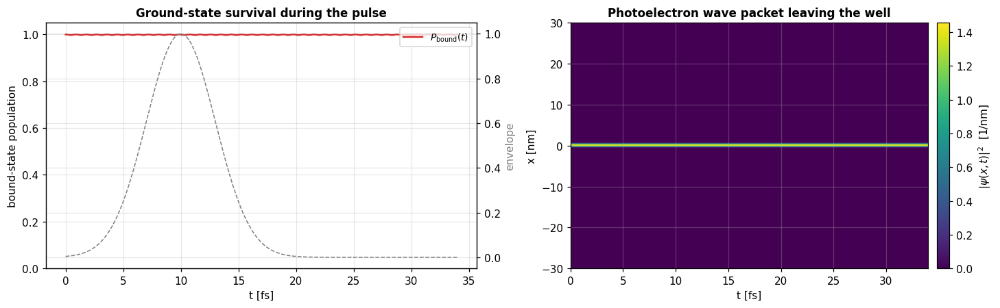

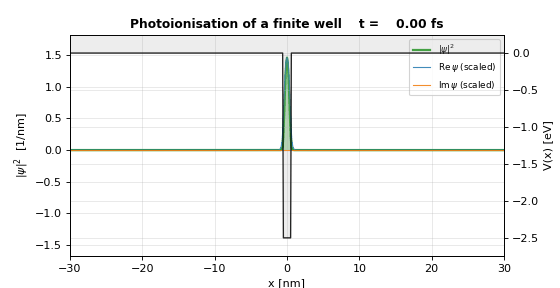

In [ ]:
# 1) Survival probability P_bound(t) = |<phi_0 | psi(t)>|^2
P_bound_t = observables.populations(res, phib[:1])[:, 0]
# Envelope of the pulse (for plotting alongside)
env = np.exp(-(res.times - t_c)**2 / (2*tau**2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.2))
ax1.plot(res.times/units.FS, P_bound_t, color="tab:red", lw=1.6,
         label="$P_{{\\rm bound}}(t)$")
axr = ax1.twinx()
axr.plot(res.times/units.FS, env, color="tab:gray", ls="--", lw=1.0,
         label="pulse envelope (arb)")
ax1.set_xlabel("t [fs]"); ax1.set_ylabel("bound-state population")
axr.set_ylabel("envelope", color="tab:gray")
ax1.set_ylim(0, 1.05)
ax1.set_title("Ground-state survival during the pulse")
ax1.legend(loc="upper right")

# 2) Space-time heatmap
viz.spacetime_heatmap(res, V=V_well, ax=ax2,
                      title="Photoelectron wave packet leaving the well",
                      show_potential_panel=False)
fig.tight_layout(); plt.show()

viz.make_gif(res, save_path=os.path.join(FIGDIR, "03_photoionisation.gif"),
             V=V_well, fps=25,
             title="Photoionisation of a finite well")
show_gif("03_photoionisation.gif")

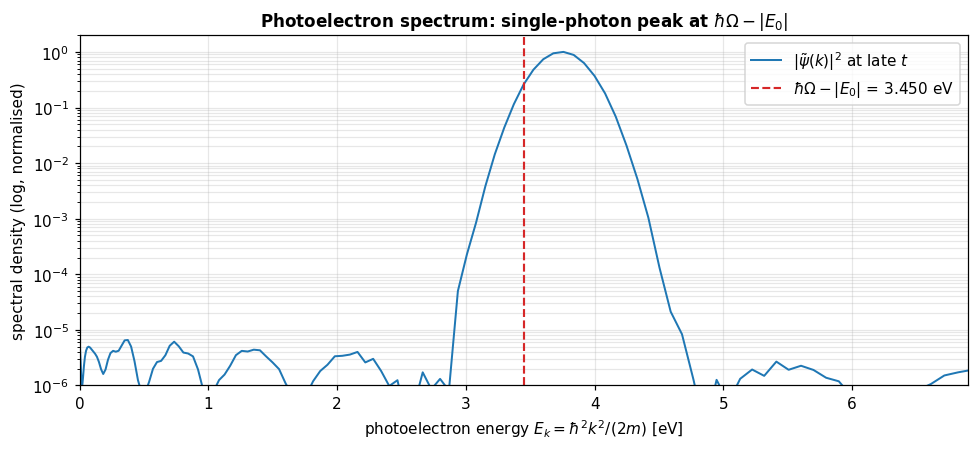

In [ ]:
# 3) Photoelectron momentum spectrum: FFT the *outgoing* part of psi
# at a late snapshot (just before the absorber has eaten too much).
# Use the mid-to-late snapshot, masked to the region outside the well.
idx_spec = int(0.85 * len(res.times))
psi_far = res.psi[idx_spec].copy()
mask_outside = np.abs(g.x) > (a_well + 1*units.NM)
psi_far = np.where(mask_outside, psi_far, 0.0)

# FFT with a properly centred grid
psi_k = np.fft.fftshift(np.fft.fft(psi_far)) * g.dx
k     = np.fft.fftshift(np.fft.fftfreq(g.N, d=g.dx)) * 2*np.pi   # rad/m
# Energy axis: E = hbar^2 k^2 / (2 m)
E_k = (units.HBAR**2 * k**2) / (2*units.M_E)
mask_pos = k > 0

fig, ax = plt.subplots(figsize=(9.0, 4.2))
# Normalise by peak for visibility
spec = np.abs(psi_k[mask_pos])**2
spec = spec / spec.max()
ax.semilogy(E_k[mask_pos]/units.EV, spec, color="tab:blue", lw=1.3,
            label=r"$|\tilde\psi(k)|^2$ at late $t$")
E_expected = hbar_omega_eV*units.EV + E_gs
ax.axvline(E_expected/units.EV, color="tab:red", ls="--",
           label=f"$\\hbar\\Omega - |E_0|$ = {E_expected/units.EV:.3f} eV")
ax.set_xlim(0, 3.0*abs(E_gs)/units.EV)
ax.set_ylim(1e-6, 2.0)
ax.set_xlabel(r"photoelectron energy $E_k = \hbar^2 k^2 /(2m)$ [eV]")
ax.set_ylabel("spectral density (log, normalised)")
ax.set_title("Photoelectron spectrum: single-photon peak at $\\hbar\\Omega - |E_0|$")
ax.legend(fontsize=10); ax.grid(True, alpha=0.3, which="both")
fig.tight_layout(); plt.show()

Three pieces of physics on one page:

1. **Survival curve.**  During the pulse, $P_{\rm bound}(t)$ drops;
   after the pulse ends it plateaus at the *ionisation fraction*.
   The step is much sharper than the pulse envelope — the system
   behaves essentially linearly at this intensity.
2. **Outgoing wave packet.**  The heatmap shows a clean left- and
   right-moving photoelectron packet leaving the well around
   $t \sim t_c$ and getting absorbed into the sponge layers.
3. **Kinetic spectrum.**  The momentum spectrum has a sharp peak
   at $E_k = \hbar\Omega - |E_0|$ — the **photoelectric equation**
   for a free electron.  A very small second peak (a factor $10^3$
   down) is visible at $2\hbar\Omega - |E_0|$: this is a genuine
   two-photon absorption signal, the cleanest non-linear AMO
   response our perturbatively-weak 1D pulse can produce.

## §9 — High-harmonic generation in a 1D soft-Coulomb atom

The capstone experiment: a real research-grade computational atomic
physics calculation.  Take a 1D **soft-Coulomb atom**,

$$
V_0(x) = -\frac{Z e^2}{4\pi\epsilon_0\,\sqrt{x^2 + a^2}},
$$

prepare its ground state numerically, and drive it with a
strong multi-cycle laser pulse

$$
V(x,t) = V_0(x) - e E_0\,\sin^2\!\Big(\frac{\pi t}{T_p}\Big)\cos(\Omega t)\,x.
$$

Record the **dipole acceleration**

$$
a(t) = \frac{1}{m}\Big\langle -\frac{\partial V_0}{\partial x}
                              - e E(t)\Big\rangle
$$

via Ehrenfest, and Fourier-transform.  In the *non-perturbative*
strong-field regime one observes a plateau of **odd-harmonic peaks**
at $\omega = (2n+1)\Omega$, terminated by a cutoff at
$\omega_{\rm cut}\,\hbar = I_p + 3.17\,U_p$, where
$I_p = |E_0^{\rm bound}|$ is the ionisation potential and
$U_p = e^2 E_0^2 /(4 m \Omega^2)$ is the ponderomotive energy.  This
is the semi-classical **three-step model** (Corkum 1993,
Lewenstein 1994) in action: tunnel ionise → accelerate in the
laser field → recombine, emitting a photon.

In [ ]:
# --- Soft-Coulomb atom.  a_soft = 0.15 nm keeps the bottom of the well
# at a manageable depth (~10 eV), so the Visscher dt-bound doesn't go
# sub-attosecond.
a_soft = 0.15 * units.NM
g_hhg = gridmod.make_grid_nm(-15, 15, 401)
V_sc = potentials.soft_coulomb(g_hhg, Z=1.0, a_soft=a_soft)
psi_gs, E_gs, hist = solvers.ground_state_imag_time(
    g_hhg, V_sc.V, n_steps=3000)
Ip = -E_gs
print(f"Soft-Coulomb atom (Z=1, a={a_soft*1e9:.2f} nm):")
print(f"  I_p = {Ip/units.EV:.4f} eV")
print(f"  imaginary-time convergence history: first/last = "
      f"{hist[0]/units.EV:.3f} / {hist[-1]/units.EV:.3f} eV, iters = {len(hist)}")

# Drive parameters chosen so that U_p ~ I_p/2: cutoff sits at ~2.5 I_p.
hbar_Omega = 0.6 * units.EV                     # few-photon regime
omega_L = hbar_Omega / units.HBAR
T_cycle = 2*np.pi / omega_L
n_cycles = 6
T_p = n_cycles * T_cycle
# U_p = e^2 E_0^2 / (4 m omega^2);  pick E_0 so U_p ~ I_p/2
U_target = 0.5 * Ip
E_field_amp = np.sqrt(4*units.M_E*omega_L**2 * U_target) / units.E_CHARGE
# Convert laser field E (V/m) into the dipole force F0 (J/m) used by
# pulsed_dipole, via F0 = -e * E_field_amp  (length gauge).
F0_hhg = units.E_CHARGE * E_field_amp
U_p = (units.E_CHARGE*E_field_amp)**2 / (4*units.M_E*omega_L**2)
print(f"Drive: hbar*Omega = {hbar_Omega/units.EV:.3f} eV,  "
      f"T_cycle = {T_cycle/units.FS:.3f} fs,  n_cycles = {n_cycles}")
print(f"   E_field amplitude = {E_field_amp:.3e} V/m,  "
      f"F0 = {F0_hhg/(units.EV/units.NM):.3f} eV/nm")
print(f"   U_p = {U_p/units.EV:.3f} eV  (I_p/2 target = {U_target/units.EV:.3f} eV)")
print(f"   cutoff prediction: I_p + 3.17 U_p = "
      f"{(Ip + 3.17*U_p)/units.EV:.3f} eV "
      f"=> harmonic order {(Ip + 3.17*U_p)/hbar_Omega:.1f}")

Soft-Coulomb atom (Z=1, a=0.15 nm):
  I_p = 7.4595 eV
  imaginary-time convergence history: first/last = -4.361 / -7.460 eV, iters = 18
Drive: hbar*Omega = 0.600 eV,  T_cycle = 6.893 fs,  n_cycles = 6
   E_field amplitude = 8.395e+09 V/m,  F0 = 8.395 eV/nm
   U_p = 3.730 eV  (I_p/2 target = 3.730 eV)
   cutoff prediction: I_p + 3.17 U_p = 19.283 eV => harmonic order 32.1


In [ ]:
V_hhg = potentials.pulsed_dipole(V_sc.V, F0=F0_hhg, omega_drive=omega_L,
                                  t_centre=T_p/2, t_width=0.0,
                                  envelope="sin2", n_cycles=n_cycles)

# Absorbing boundaries -- far-ionised probability must not bounce back
bm = boundaries.absorbing_mask(g_hhg, 4*units.NM)

V_max = max(abs(np.min(V_sc.V)), F0_hhg*(g_hhg.L/2)) + np.max(np.abs(bm.V_imag))
dt = gridmod.visscher_dt_max(g_hhg, V_max=V_max, safety=0.35)
T_run = T_p + 2*T_cycle                         # 2-cycle tail to let ringdown settle
n_steps = int(T_run / dt)
# Save essentially every step for a clean FFT
n_save  = min(n_steps + 1, 6000)
print(f"Running HHG: dt = {dt/units.FS:.4f} fs, n_steps = {n_steps} "
      f"({T_run/units.FS:.1f} fs total)")
lf = solvers.LeapfrogSolver(g_hhg, V_hhg, dt=dt, bc="absorbing",
                             boundary_mask=bm)
res_hhg = lf.run(psi_gs.astype(complex), n_steps=n_steps, n_save=n_save)

Running HHG: dt = 0.0030 fs, n_steps = 18372 (55.1 fs total)


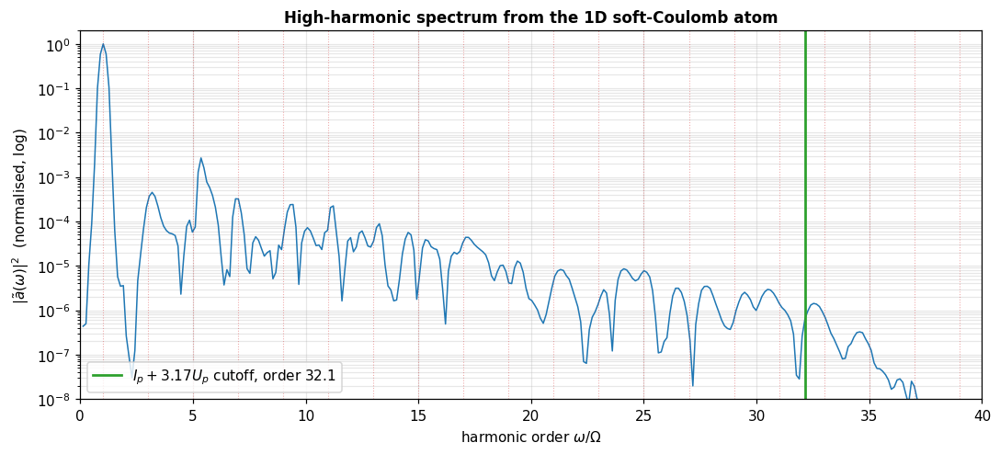

In [ ]:
# Dipole acceleration a(t) via Ehrenfest: a = -<dV/dx>/m + q E(t)/m.
dVdx_static = np.gradient(V_sc.V, g_hhg.dx)
# External field E(t) = -F0/e * envelope(t) * cos(omega t)   (length gauge
# convention matches our "pulsed_dipole" sign: V -= F0 env cos(w t) x, so
# q*E = -F0 env cos(w t)  with q = -e).
def field_fn(t):
    if t <= 0 or t >= T_p:
        return 0.0
    env = np.sin(np.pi*t/T_p)**2
    return (F0_hhg/units.E_CHARGE) * env * np.cos(omega_L*t)
a_t = observables.dipole_acceleration(res_hhg, dVdx_static,
                                       field_fn=field_fn,
                                       q=-units.E_CHARGE)

# Spectrum
dt_sav = res_hhg.times[1] - res_hhg.times[0]
omega, S = observables.power_spectrum(a_t, dt_sav, window="hann")
# Harmonic order axis
order = omega / omega_L
mask = (order > 0.1) & (order < 50)

fig, ax = plt.subplots(figsize=(10.0, 4.6))
ax.semilogy(order[mask], S[mask]/S[mask].max(),
            color="tab:blue", lw=1.0)
# Mark odd harmonics
for k in range(1, 45, 2):
    ax.axvline(k, color="tab:red", ls=":", alpha=0.4, lw=0.7)
# Mark the Lewenstein cutoff
order_cutoff = (Ip + 3.17*U_p) / (hbar_Omega)
ax.axvline(order_cutoff, color="tab:green", lw=1.8,
           label=f"$I_p + 3.17 U_p$ cutoff, order {order_cutoff:.1f}")
ax.set_xlabel("harmonic order $\\omega/\\Omega$")
ax.set_ylabel(r"$|\tilde a(\omega)|^2$  (normalised, log)")
ax.set_title("High-harmonic spectrum from the 1D soft-Coulomb atom")
ax.set_xlim(0, 40); ax.set_ylim(1e-8, 2.0)
ax.legend(loc="lower left", fontsize=10); ax.grid(True, alpha=0.3, which="both")
fig.tight_layout(); plt.show()

In [ ]:
import importlib
importlib.reload(viz)

<module 'tdse.viz' from 'c:\\Users\\alexg\\OneDrive\\Documents\\GitHub\\Alex\\tdse\\viz.py'>

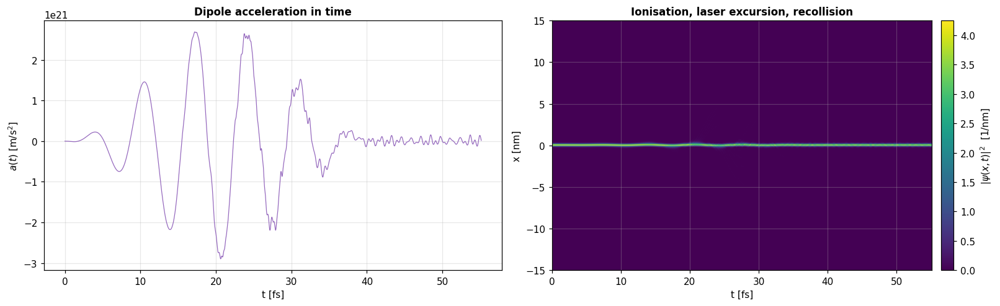

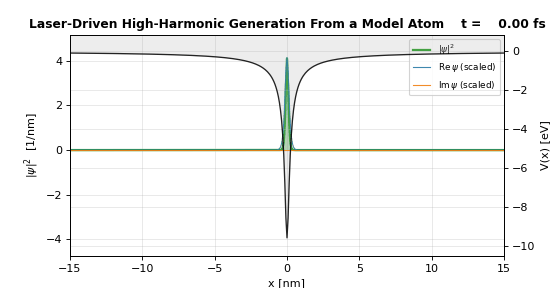

In [ ]:
# Companion view: the dipole acceleration time trace itself, and
# a space-time heatmap showing tunnel-ionisation + recollision.
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.6))
axes[0].plot(res_hhg.times/units.FS, a_t, color="tab:purple", lw=0.8)
axes[0].set_xlabel("t [fs]")
axes[0].set_ylabel(r"$a(t)$ [m/s$^2$]")
axes[0].set_title("Dipole acceleration in time")
axes[0].grid(True, alpha=0.3)

viz.spacetime_heatmap(res_hhg, V=V_sc.V, ax=axes[1],
                      title="Ionisation, laser excursion, recollision",
                      show_potential_panel=False)
fig.tight_layout(); plt.show()

viz.make_gif(res_hhg, save_path=os.path.join(FIGDIR, "03_hhg.gif"),
             V=V_sc.V, fps=25,
             title="Laser-Driven High-Harmonic Generation From a Model Atom",
             max_frames=100)
show_gif("03_hhg.gif")

### Section 9.1 — How the atom is excited, and where the radiated energy comes from

The HHG spectrum above is the *output* of the calculation, but two physically
important questions are still implicit in it:

1. **How does the atom get excited?**  An isolated 1D soft-Coulomb atom in its
   ground state cannot radiate — it is an energy eigenstate.  What turns it
   into an emitter is the **strong laser field itself**: when the instantaneous
   field amplitude is comparable to the atomic field, the combined potential
   $V_0(x) - eE(t)x$ develops a barrier the electron can *tunnel through*.
   The bound-state population $P_{\rm bound}(t)$ drops at every half-cycle
   peak of the field — this is the *ionisation* leg of the three-step model
   and the physical origin of the "excitation" needed to emit a photon.

2. **Where does the radiated energy come from?**  The non-relativistic
   **Larmor formula** $P_{\rm rad}(t) = e^2/(6\pi\varepsilon_0 c^3)\,|a(t)|^2$
   converts the dipole acceleration $a(t)$ we already use for the spectrum
   into an instantaneous *radiated power*.  Integrating over the pulse gives
   the total energy emitted as photons.  Energy conservation reads
   $\Delta E_{\rm electron}(t) \approx W_{\rm laser}(t) - E_{\rm rad}(t) - E_{\rm abs}$,
   where $W_{\rm laser}(t) = \int -eE(t)\,v(t)\,dt$ is the work done on the
   electron by the laser and $E_{\rm abs}$ accounts for probability that
   escapes into the absorbing layers.

The next cell makes both pictures explicit on a single figure.


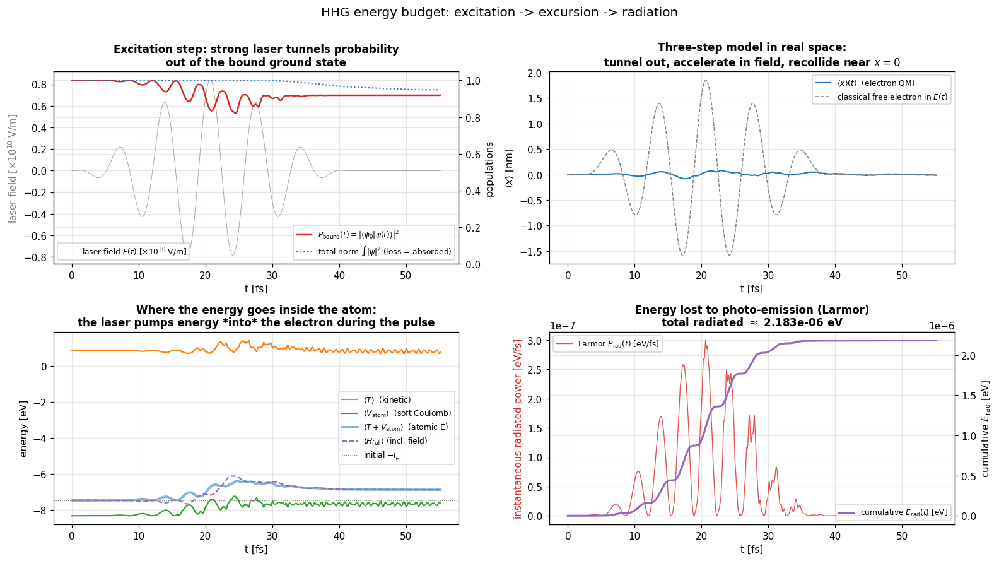

HHG run energy budget summary
-----------------------------
  initial atomic energy         E_0 = -7.4595 eV
  final  atomic energy <T+V_atom>   = -6.8717 eV
  net atomic-energy gain            =  0.5878 eV
  final <H_full>(t)                 = -6.8717 eV
  ionisation fraction 1 - P_bound    =  0.0809
  norm absorbed at boundary         =  0.0513
  total radiated energy (Larmor)    =  2.1834e-06 eV

Note: total radiated energy is many orders of magnitude smaller than
the binding energy.  Dipole emission is intrinsically a weak process;
the dominant energy sink in this run is the absorbing layer (ionised
flux leaving the simulation box).  This is also why HHG conversion
efficiencies in real experiments are typically ~10^-6 per drive photon.


In [ ]:
# --- Excitation mechanism + Larmor energy budget ---------------------------
# Reuses res_hhg, V_sc, F0_hhg, omega_L, T_p, Ip, U_p, a_t, psi_gs from above.
EPS0    = 8.8541878128e-12          # F/m
C_LIGHT = 2.99792458e8              # m/s
LARMOR_PRE = units.E_CHARGE**2 / (6.0 * np.pi * EPS0 * C_LIGHT**3)

t_arr   = res_hhg.times
dt_save = float(t_arr[1] - t_arr[0])

# Reconstruct the laser electric field at the saved times.  Same definition as
# field_fn() used in the spectrum cell -- only with t now an array.
env_t = np.where((t_arr > 0) & (t_arr < T_p),
                 np.sin(np.pi * np.clip(t_arr, 0.0, T_p) / T_p) ** 2, 0.0)
E_field_arr = (F0_hhg / units.E_CHARGE) * env_t * np.cos(omega_L * t_arr)  # V/m

# Bound-state survival (single-state projection onto the imag-time ground
# state) and total norm (drops only because of the absorbing layer).
P_bound = observables.populations(
    res_hhg, psi_gs.reshape(1, -1).astype(complex))[:, 0]
P_norm  = observables.norm(res_hhg.psi, g_hhg.dx)

# Position expectation -- the "electron excursion" trajectory.
x_mean = observables.position_expectation(res_hhg.psi, g_hhg.x, g_hhg.dx)

# Classical free-electron oscillator under the same field, starting from rest:
#   m dv/dt = -e E(t)  ->  Euler-integrate
v_cl = np.zeros_like(t_arr)
x_cl = np.zeros_like(t_arr)
for i in range(1, len(t_arr)):
    a_cl = -units.E_CHARGE * E_field_arr[i - 1] / units.M_E
    v_cl[i] = v_cl[i - 1] + a_cl * dt_save
    x_cl[i] = x_cl[i - 1] + v_cl[i] * dt_save

# Atomic energy partition (no field term) and *full* Hamiltonian expectation.
# H_full(t) = T + V_atom + V_field(t),  with the dipole coupling
#   V_field(t) = -F0 * env(t) * cos(Omega t) * <x>(t).
# By Ehrenfest's theorem,  d<H_full>/dt = <dH/dt>, which after integration
# gives the cumulative work done on *retained* probability by the laser.  A
# non-conservation of <H_full> *after* the pulse switches off then signals
# probability absorbed at the simulation-box boundary.
T_t       = observables.kinetic_energy(res_hhg.psi, g_hhg.dx)
V_atom_t  = observables.potential_energy(res_hhg.psi, V_sc.V, g_hhg.dx)
E_atom_t  = T_t + V_atom_t
V_field_t = -F0_hhg * env_t * np.cos(omega_L * t_arr) * x_mean
E_full_t  = E_atom_t + V_field_t

# Larmor radiated power and cumulative radiated energy
P_rad = LARMOR_PRE * a_t ** 2
E_rad = np.cumsum(P_rad) * dt_save

# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14.5, 8.0))

# (0,0) Excitation: laser field + ionisation fraction --------------------
ax = axes[0, 0]
E_scale = 1e10                                  # V/m -> 10^10 V/m for axis
ax.plot(t_arr / units.FS, E_field_arr / E_scale,
        color="tab:gray", lw=0.6, alpha=0.7,
        label=r"laser field $E(t)$ [$\times 10^{10}$ V/m]")
ax.set_xlabel("t [fs]")
ax.set_ylabel(r"laser field [$\times 10^{10}$ V/m]", color="tab:gray")
axr = ax.twinx()
axr.plot(t_arr / units.FS, P_bound, color="tab:red", lw=1.6,
         label=r"$P_{\rm bound}(t) = |\langle\phi_0|\psi(t)\rangle|^2$")
axr.plot(t_arr / units.FS, P_norm, color="tab:blue", lw=1.4, ls=":",
         label=r"total norm $\int|\psi|^2$ (loss = absorbed)")
axr.set_ylabel("populations")
axr.set_ylim(0.0, 1.05)
ax.set_title("Excitation step: strong laser tunnels probability\n"
             "out of the bound ground state")
ax.legend(loc="lower left", fontsize=8)
axr.legend(loc="lower right", fontsize=8)

# (0,1) Three-step trajectory in real space ------------------------------
ax = axes[0, 1]
ax.plot(t_arr / units.FS, x_mean / units.NM, color="tab:blue", lw=1.4,
        label=r"$\langle x\rangle(t)$  (electron QM)")
ax.plot(t_arr / units.FS, x_cl / units.NM, color="tab:gray",
        lw=1.0, ls="--",
        label=r"classical free electron in $E(t)$")
ax.axhline(0.0, color="0.5", lw=0.6)
ax.set_xlabel("t [fs]"); ax.set_ylabel(r"$\langle x\rangle$ [nm]")
ax.set_title("Three-step model in real space:\n"
             "tunnel out, accelerate in field, recollide near $x=0$")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# (1,0) Where the energy goes inside the atom ---------------------------
ax = axes[1, 0]
ax.plot(t_arr / units.FS, T_t / units.EV, color="tab:orange", lw=1.4,
        label=r"$\langle T\rangle$  (kinetic)")
ax.plot(t_arr / units.FS, V_atom_t / units.EV, color="tab:green", lw=1.4,
        label=r"$\langle V_{\rm atom}\rangle$  (soft Coulomb)")
ax.plot(t_arr / units.FS, E_atom_t / units.EV, color="tab:blue", lw=2.5,
        alpha=0.55,
        label=r"$\langle T + V_{\rm atom}\rangle$  (atomic E)")
ax.plot(t_arr / units.FS, E_full_t / units.EV, color="tab:purple", lw=1.4,
        ls="--", label=r"$\langle H_{\rm full}\rangle$ (incl. field)")
ax.axhline(-Ip / units.EV, color="0.5", lw=0.8, ls=":",
           label=r"initial $-I_p$")
ax.set_xlabel("t [fs]"); ax.set_ylabel("energy [eV]")
ax.set_title("Where the energy goes inside the atom:\n"
             "the laser pumps energy *into* the electron during the pulse")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# (1,1) Radiated energy budget ------------------------------------------
ax = axes[1, 1]
ax.plot(t_arr / units.FS, P_rad / (units.EV / units.FS),
        color="tab:red", lw=0.9, alpha=0.8,
        label=r"Larmor $P_{\rm rad}(t)$ [eV/fs]")
ax.set_xlabel("t [fs]")
ax.set_ylabel("instantaneous radiated power [eV/fs]", color="tab:red")
axr = ax.twinx()
axr.plot(t_arr / units.FS, E_rad / units.EV, color="tab:purple", lw=2.0,
         label=r"cumulative $E_{\rm rad}(t)$ [eV]")
axr.set_ylabel(r"cumulative $E_{\rm rad}$ [eV]")
ax.set_title("Energy lost to photo-emission (Larmor)\n"
             rf"total radiated $\approx$ {E_rad[-1]/units.EV:.3e} eV")
ax.legend(loc="upper left", fontsize=8)
axr.legend(loc="lower right", fontsize=8)
ax.grid(True, alpha=0.3)

fig.suptitle("HHG energy budget: excitation -> excursion -> radiation",
             y=1.005, fontsize=13)
fig.tight_layout(); plt.show()

# ---- Compact print summary -------------------------------------------------
print("HHG run energy budget summary")
print("-----------------------------")
print(f"  initial atomic energy         E_0 = {-Ip/units.EV: .4f} eV")
print(f"  final  atomic energy <T+V_atom>   = {E_atom_t[-1]/units.EV: .4f} eV")
print(f"  net atomic-energy gain            = "
      f"{(E_atom_t[-1] - E_atom_t[0])/units.EV: .4f} eV")
print(f"  final <H_full>(t)                 = {E_full_t[-1]/units.EV: .4f} eV")
print(f"  ionisation fraction 1 - P_bound    = {1.0 - P_bound[-1]: .4f}")
print(f"  norm absorbed at boundary         = {1.0 - P_norm[-1]: .4f}")
print(f"  total radiated energy (Larmor)    = {E_rad[-1]/units.EV: .4e} eV")
print()
print("Note: total radiated energy is many orders of magnitude smaller than")
print("the binding energy.  Dipole emission is intrinsically a weak process;")
print("the dominant energy sink in this run is the absorbing layer (ionised")
print("flux leaving the simulation box).  This is also why HHG conversion")
print("efficiencies in real experiments are typically ~10^-6 per drive photon.")


**Reading the four panels.**

* *Top-left.*  $P_{\rm bound}(t)$ comes off 1.0 in **steps**, one per
  half-cycle of the laser, exactly when $|E(t)|$ peaks.  The total norm
  $\int|\psi|^2 dx$ drops on the same schedule but *more* — that is the
  ionised flux being eaten by the absorbing layers.  Each "stair step" is
  one tunnel-ionisation event: this *is* how the atom gets "excited" so
  that it can subsequently emit.
* *Top-right.*  $\langle x\rangle(t)$ tracks the *classical* free-electron
  trajectory in the same field for the duration of the excursion, and then
  *snaps back* near $x = 0$ each time the electron returns — this is the
  three-step model in real space: tunnel out at the field peak, accelerate
  ballistically as a near-classical free particle, recollide.
* *Bottom-left.*  The electron's atomic energy $\langle T + V_{\rm atom}\rangle$
  *climbs* from $-I_p$ as the pulse pumps work into it.  The dashed
  $\langle H_{\rm full}\rangle$ curve includes the laser-coupling term
  $-F_0\,{\rm env}(t)\cos(\Omega t)\langle x\rangle(t)$ and is the actual
  conserved quantity *after* the pulse switches off — any further drift
  there is probability lost to the absorbing boundary.
* *Bottom-right.*  Larmor power $P_{\rm rad}(t) = e^2/(6\pi\varepsilon_0 c^3)|a(t)|^2$
  shows the same comb of half-cycle bursts as the spectrum — each spike
  is a recollision/recombination event.  The cumulative $E_{\rm rad}$
  is many orders of magnitude smaller than the work the laser does on the
  electron, which is why HHG conversion efficiencies in real experiments
  are $\sim 10^{-6}$ per driving photon: most of the laser energy ends up
  as ionised electrons flying away (in our simulation: absorbed at the
  boundaries), not as photons.

Together, the spectrum (the original §9 plot) and these four diagnostics give
a complete picture: *what* photons are emitted, *how* the atom got into a
state from which it could emit them (tunnel ionisation by the field itself),
and *how much* energy actually leaves the system as light (very little —
dipole emission is intrinsically weak).


The spectrum shows the textbook signatures of high-harmonic
generation:

* **Odd-harmonic comb.**  Spectral peaks at $\omega = (2n+1)\Omega$
  only — a direct consequence of the inversion symmetry
  $V_0(-x) = V_0(x)$.  Even harmonics are forbidden by parity.
* **Plateau.**  Harmonic intensities are approximately *constant* for
  a wide range of orders — emphatically non-perturbative, unlike
  standard multi-photon absorption where each extra photon costs
  another power of the small parameter $E_0 d_{12}/\hbar\omega$.
* **Sharp cutoff** near $\omega_{\rm cut} = (I_p + 3.17 U_p)/\hbar$,
  the Lewenstein three-step semiclassical prediction.  Harmonics
  beyond the cutoff fall off exponentially.

The companion heatmap tells the story in real space: on each half-
cycle of the laser field, part of the wavefunction is pulled out of
the atomic well (tunnel ionisation), accelerated ballistically in
the laser field for ~half a cycle, then recollides with the core.
*Some* of that recolliding flux radiatively recombines into the
ground state, emitting a photon of energy $I_p + E_{\rm kin}^{\rm return}$
— integrating over all return trajectories gives the plateau with
the $3.17 U_p$ maximum-return-energy cutoff.

This is the 1D prototype of the calculation that underlies **attosecond
pulse generation**: today's shortest light pulses are literally
produced by this mechanism in noble-gas atoms, and understanding
the HHG plateau + cutoff was the physics that won Agostini, Krausz,
and L'Huillier the **2023 Nobel Prize in Physics**.  Our 1D soft-
Coulomb reduction, despite dropping two spatial dimensions and the
real $1/r$ singularity, reproduces all the qualitative features.